# DAWN — Entraînement du modèle ECG pédiatrique (**V6**, exécution longue) — Kaggle

**Multi-label, 12 catégories AHA (A, C–H, I–M)** — fusion ECG 12 dérivations + âge + sexe.

### Ce qui change par rapport à la V4 (corrections de la V4 exécutée)
| # | Problème constaté dans la V4 | Correction V5 |
|---|---|---|
| 1 | **Âge et sexe valaient toujours 0** (format réel `572d` et `'Male'` non reconnu) → la branche clinique ne servait à rien | parsing correct + **assertions** qui arrêtent le notebook si les features sont constantes |
| 2 | La stratégie (ASL vs CB) était choisie **sur le test** | choix sur la **validation** (mAP), le test n'est regardé qu'à la fin |
| 3 | Poids de la **dernière** epoch utilisés, pas les meilleurs | poids du **meilleur epoch** (mAP validation) + moyenne exponentielle des poids (EMA) |
| 4 | Aucune normalisation du signal | suppression de la ligne de base + mise à l'échelle par enregistrement |
| 5 | Évaluation sur les **10 premières secondes seulement** (les ECG durent 13–34 s) | **5 fenêtres** réparties sur tout l'enregistrement, probabilités moyennées |
| 6 | 1 seul entraînement (résultats instables, surtout G et M) | meilleure architecture : **3 graines × 2 fonctions de perte**, ensemble, intervalles de confiance bootstrap |
| 7 | Un seul type de modèle | **tournoi de 5 architectures** : CNN1D, ResNet1D, **ConvNeXt1D**, **Vision Transformer 1D**, **HuBERT-ECG** (modèle Hugging Face pré-entraîné sur 9,1 M d'ECG, fine-tuné) ; la meilleure (sur la validation) est ensuite entraînée avec 3 graines × 2 pertes + ablations (clinique seule, sans âge/sexe) |
| 8 | Entraînement court (22 epochs, arrêt prématuré) | jusqu'à 50 epochs, planning cosinus, patience 12 |

### Nouveauté V6 : approche probabiliste (sans IA générative)
Calibration des probabilités (ECE, Brier), incertitude par désaccord entre modèles et entropie, **prédiction conforme** (garantie de couverture par catégorie), abstention (courbe risque-couverture) et seuils orientés sécurité (rappel ≥ 90 %). Les **figures s'affichent maintenant dans le notebook** : elles sont conservées dans le .ipynb téléchargé.

### Avant de lancer
1. *Add Input* : le dataset ZZU (comme pour la V4). *Settings* → **Accelerator : GPU T4**, **Internet : On**.
2. **Save Version → Save & Run All (Commit)** : le calcul tourne sans garder l'onglet ouvert et la sortie (`/kaggle/working`) est **conservée** dans l'onglet *Output* de la version. *Ne pas utiliser une session interactive : ses fichiers disparaissent à l'arrêt.* Durée attendue : **≈ 6 à 9 h** (le garde-fou arrête proprement à `TIME_BUDGET_H`). Un garde-fou arrête proprement l'entraînement à `TIME_BUDGET_H` heures.
3. Si la session coupe : ajoute la **sortie** de la version précédente en *Input* puis relance — les runs déjà terminés sont **réutilisés**, les epochs interrompues **reprises**.

### À me renvoyer à la fin
Le notebook exécuté (.ipynb avec ses sorties) **et** `dawn_v5_results.zip` (figures PNG, tableaux CSV, JSON) disponible dans l'onglet *Output*. Le fichier `models/dawn_ecg_model_final.pt` n'est utile que pour le backend, pas pour le mémoire. *(HuBERT-ECG est téléchargé depuis Hugging Face : Internet doit être activé ; s'il est inaccessible, ce modèle est simplement ignoré.)*

In [1]:
import os, sys, json, math, time, random, shutil, subprocess, re, zipfile, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
T_START = time.time()
def elapsed_h(): return (time.time() - T_START) / 3600

# ============================ CONFIGURATION ============================
FAST_TEST     = os.environ.get("DAWN_FAST", "0") == "1"   # test rapide (CPU, données synthétiques) : laisser à "0" sur Kaggle
SEEDS         = [42] if FAST_TEST else [42, 1337, 2024]   # nb de graines par fonction de perte
LOSSES        = ["ASL", "CB"]
N_EPOCHS      = 2 if FAST_TEST else 50
PATIENCE      = 12                                         # early stopping sur la mAP de validation
WARMUP_EP     = 1 if FAST_TEST else 3
LR, WEIGHT_DECAY = 1e-3, 1e-2
BATCH_SIZE    = 16 if FAST_TEST else 32
EMA_DECAY     = 0.9 if FAST_TEST else 0.998
N_EVAL_WIN    = 5           # fenêtres de 10 s réparties sur l'enregistrement (validation finale + test)
N_VAL_WIN     = 2           # fenêtres utilisées pendant l'entraînement (plus rapide)
TIME_BUDGET_H = 10.5        # garde-fou global (la session Kaggle est limitée à ~12 h)
# --- Tournoi d'architectures (étape A) : une graine, une fonction de perte, toutes les architectures ---
ARCHS         = ["resnet", "cnn", "convnext", "vit", "hubert"]
ARCH_LOSS     = "CB"                                       # fonction de perte utilisée pour le tournoi
ARCH_LR       = {"vit": 5e-4}                              # lr par architecture (défaut : LR)
HUBERT_BB_LR  = 3e-5                                       # lr du backbone pré-entraîné (la tête et la branche clinique utilisent LR)
HF_IDS        = ["Edoardo-Coppola/hubert-ecg-small", "Edoardo-BS/hubert-ecg-small"]   # modèle Hugging Face (HuBERT-ECG, 30 M de paramètres)
HF_IDS_BASE   = ["Edoardo-Coppola/hubert-ecg-base", "Edoardo-BS/hubert-ecg-base"]     # version « base » (93 M) : pour la tester, ajouter "hubert_base" à ARCHS ci-dessus (≈ +1 h de GPU)
RUN_ABLATIONS = True
N_MC          = 3 if FAST_TEST else 20
N_BOOT        = 50 if FAST_TEST else 1000
NORM_MODE     = "record"    # "record" : un facteur d'échelle par ECG (conserve les rapports d'amplitude entre dérivations) | "lead" : z-score par dérivation
BASELINE_REMOVAL = True     # soustrait une moyenne glissante de 1 s (≈ filtre passe-haut 0,5 Hz) pour retirer la dérive de ligne de base
print(f"FAST_TEST={FAST_TEST} | seeds={SEEDS} | epochs max={N_EPOCHS} | budget={TIME_BUDGET_H} h")

FAST_TEST=False | seeds=[42, 1337, 2024] | epochs max=50 | budget=10.5 h


In [2]:
try:
    import wfdb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=False)
    try:
        import wfdb
    except ImportError:
        wfdb = None
        print("⚠️ wfdb non installé (Internet désactivé ?). OK seulement si les signaux sont en .npy/.mat")

KAGGLE_INPUT = Path(os.environ.get("DAWN_INPUT", "/kaggle/input"))
WORK_DIR     = Path(os.environ.get("DAWN_WORK", "/kaggle/working"))

def _find_parent_of(filename):
    hits = sorted(KAGGLE_INPUT.rglob(filename), key=lambda p: len(p.parts))
    if not hits:
        raise FileNotFoundError(f"'{filename}' introuvable sous {KAGGLE_INPUT}. Vérifie le dataset (+ Add Input) : !ls /kaggle/input")
    return hits[0].parent

REF_DIR    = _find_parent_of("AttributesDictionary.csv")
SPLITS_DIR = _find_parent_of("ecg_train.csv")
CKPT_DIR   = WORK_DIR / "checkpoints"
MODELS_DIR = WORK_DIR / "models"
RES_DIR    = WORK_DIR / "results"
RUNS_DIR   = RES_DIR / "runs"
FIG_DIR    = RES_DIR / "figures"
for d in (CKPT_DIR, MODELS_DIR, RES_DIR, RUNS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Index des signaux : ECG_ID -> {extension: chemin}
t0 = time.time()
SIGNAL_INDEX = {}
for p in KAGGLE_INPUT.rglob("*"):
    if p.suffix in (".npy", ".mat", ".hea"):
        SIGNAL_INDEX.setdefault(p.stem, {})[p.suffix] = p
print(f"{len(SIGNAL_INDEX)} signaux indexés en {time.time()-t0:.0f}s")

# Reprise : sorties d'une exécution précédente ajoutée en Input (runs terminés, checkpoints, meilleurs poids)
if KAGGLE_INPUT != WORK_DIR:
    for pattern, dest in (("run_*.npz", RUNS_DIR), ("*_resume.pt", CKPT_DIR), ("*_best.pt", MODELS_DIR)):
        for p in KAGGLE_INPUT.rglob(pattern):
            if not (dest / p.name).exists():
                shutil.copy(p, dest / p.name); print("récupéré :", p.name)

random.seed(42); np.random.seed(42)
print("REF_DIR   :", REF_DIR); print("SPLITS_DIR:", SPLITS_DIR); print("Sorties   :", WORK_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 2.3 MB/s eta 0:00:00
14190 signaux indexés en 14s
REF_DIR   : /kaggle/input/datasets/adamarahma/zzu-ecg/ECG
SPLITS_DIR: /kaggle/input/datasets/adamarahma/zzu-ecg/ECG/splits
Sorties   : /kaggle/working


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = (DEVICE.type == "cuda")
print("Device :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
else:
    print("⚠️ Pas de GPU : Settings → Accelerator → GPU T4, puis Restart & Run All.")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

Device : cuda
GPU    : Tesla T4


## 1. Étiquettes (12 catégories AHA, multi-label) et features cliniques
Le parsing de l'âge et du sexe est **corrigé** ; un contrôle d'absence de fuite entre patients est ajouté.

In [4]:

CATEGORIES = ['A','C','D','E','F','G','H','I','J','K','L','M']
N_CLASSES = len(CATEGORIES)
CAT2IDX = {c: i for i, c in enumerate(CATEGORIES)}

# NB formats réels observés :
#  - AttributesDictionary.csv : une ligne par ECG_ID, colonnes AHA_code / CHN_code
#    contenant des entrées séparées par ';', chaque entrée entre quotes simples,
#    ex: "'C21';'First-degree AV block';'L147'"  <->  "'C13';'H74';'L123'"
#    (positionnellement alignées : quand AHA_code[i] est un texte brut sans code
#    formel, CHN_code[i] porte le code formel correspondant à la même position)
#  - ECGCode.csv : table de référence Description -> AHA(Category&Code) / CHN(Category&Code)
#  - ecg_train/val/test.csv : les splits n'ont QUE la colonne AHA_code -> il faut
#    joindre avec AttributesDictionary.csv (clé ECG_ID) pour récupérer le CHN_code.
attrs = pd.read_csv(REF_DIR / "AttributesDictionary.csv")
ecg_codes = pd.read_csv(REF_DIR / "references/ECGCode.csv")

# Construit un dict code_formel -> catégorie (première lettre du code), à partir
# des deux colonnes de codes formels de la table de référence.
code_to_desc = {}
for _, row in ecg_codes.iterrows():
    for col in ("AHA(Category&Code)", "CHN(Category&Code)"):
        val = row.get(col)
        if pd.notna(val):
            code_to_desc[str(val).strip()] = row.to_dict()

def category_of(code_str):
    code_str = str(code_str).strip().strip("'").strip()
    if not code_str:
        return None
    first = code_str[0]
    return first if first in CATEGORIES else None

def parse_multi(raw):
    '''"C21";"First-degree AV block";"L147" -> ["C21", "First-degree AV block", "L147"]
    (retire les quotes simples autour de chaque entrée) ; gère NaN / vide.'''
    if pd.isna(raw) or str(raw).strip() == "":
        return []
    parts = [p.strip() for p in str(raw).split(';') if p.strip()]
    return [p.strip("'").strip() for p in parts]

def category_with_fallback(aha_entry, chn_entry):
    '''Résout la catégorie d'un code composite 'F60+Modifier310', avec repli CHN
    si le code AHA n'est pas un code formel reconnu (texte brut).'''
    primary_aha = aha_entry.split('+')[0].strip()
    if primary_aha in code_to_desc:
        return category_of(primary_aha)
    if chn_entry:
        primary_chn = chn_entry.split('+')[0].strip()
        return category_of(primary_chn)
    return None

def build_multihot(aha_raw, chn_raw):
    aha_codes = parse_multi(aha_raw)
    chn_codes = parse_multi(chn_raw)
    cats = set()
    for i, a in enumerate(aha_codes):
        c = chn_codes[i] if i < len(chn_codes) else ''
        cat = category_with_fallback(a, c)
        if cat in CATEGORIES:
            cats.add(cat)
    return [1 if c in cats else 0 for c in CATEGORIES]

print("Catégories :", CATEGORIES, "| N_CLASSES =", N_CLASSES)

Catégories : ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M'] | N_CLASSES = 12


In [5]:
# ---- Features cliniques : parsing CORRIGÉ (V4 : âge = NaN → 0, sexe = "'Male'" → toujours 0) ----
attrs = pd.read_csv(REF_DIR / "AttributesDictionary.csv")
attrs_idx = attrs.drop_duplicates("ECG_ID").set_index("ECG_ID")

def parse_age_years(v):
    """'572d' -> 1.57 ans ; accepte aussi m (mois), w (semaines), y (années)."""
    m = re.match(r"\s*['\"]?\s*(\d+(?:\.\d+)?)\s*([A-Za-z]*)", str(v))
    if not m:
        return np.nan
    x, u = float(m.group(1)), m.group(2).lower()[:1]
    if u == "d": return x / 365.25
    if u == "m": return x / 12.0
    if u == "w": return x / 52.18
    if u == "y": return x
    return x if x <= 18 else x / 365.25

def parse_sex_male(v):
    s = str(v).strip().strip("'\"").lower()
    return 1.0 if s.startswith("m") else 0.0

age_years_s = attrs_idx["Age"].map(parse_age_years)
age_years_s = age_years_s.fillna(age_years_s.median())
AGE_SCALE = 15.0
age_norm_s = (age_years_s / AGE_SCALE).clip(0, 1.2)
sex_m_s    = attrs_idx["Gender"].map(parse_sex_male).astype(np.float32)
pid_s      = attrs_idx["Patient_ID"] if "Patient_ID" in attrs_idx.columns else None

print(f"Âge (ans) : min={age_years_s.min():.2f} médiane={age_years_s.median():.2f} max={age_years_s.max():.2f}")
print(f"Sexe masculin : {100*sex_m_s.mean():.1f} %")
assert age_norm_s.std() > 0.05, "Feature âge constante : parsing de la colonne Age en échec"
assert 0.2 < sex_m_s.mean() < 0.8, "Feature sexe dégénérée : parsing de la colonne Gender en échec"

def load_split(name):
    df = pd.read_csv(SPLITS_DIR / f"ecg_{name}.csv")
    df["CHN_code"]  = df["ECG_ID"].map(attrs_idx["CHN_code"])
    df["age_years"] = df["ECG_ID"].map(age_years_s)
    df["age_norm"]  = df["ECG_ID"].map(age_norm_s)
    df["sex_m"]     = df["ECG_ID"].map(sex_m_s)
    df["Patient_ID"] = df["ECG_ID"].map(pid_s) if pid_s is not None else df["ECG_ID"].str.split("_").str[0]
    labels = df.apply(lambda r: build_multihot(r.get("AHA_code"), r.get("CHN_code")), axis=1)
    label_mat = np.array(labels.tolist(), dtype=np.float32)
    n_zero = int((label_mat.sum(axis=1) == 0).sum())
    print(f"[{name}] {len(df)} ECG | {df['Patient_ID'].nunique()} patients | {n_zero} sans catégorie résolue")
    return df, label_mat

train_df, train_labels = load_split("train")
val_df,   val_labels   = load_split("val")
test_df,  test_labels  = load_split("test")

# Contrôle d'absence de fuite : aucun patient dans deux partitions
P = {n: set(d["Patient_ID"]) for n, d in (("train", train_df), ("val", val_df), ("test", test_df))}
leak = {"train∩val": len(P["train"] & P["val"]), "train∩test": len(P["train"] & P["test"]), "val∩test": len(P["val"] & P["test"])}
print("Patients communs entre partitions :", leak)
assert sum(leak.values()) == 0, "Fuite patient entre partitions !"

# Statistiques de labels par partition
rows = []
for name, df, Y in (("train", train_df, train_labels), ("val", val_df, val_labels), ("test", test_df, test_labels)):
    nl = Y.sum(axis=1)
    rows.append({"partition": name, "n_ecg": len(df), "n_patients": df["Patient_ID"].nunique(),
                 "pct_multi_label(>=2 cat)": round(100 * (nl >= 2).mean(), 2),
                 "mean_labels_per_ecg": round(nl.mean(), 3),
                 **{f"n_{c}": int(Y[:, i].sum()) for i, c in enumerate(CATEGORIES)}})
all_Y = np.concatenate([train_labels, val_labels, test_labels])
rows.append({"partition": "TOTAL", "n_ecg": len(all_Y), "n_patients": len(P["train"] | P["val"] | P["test"]),
             "pct_multi_label(>=2 cat)": round(100 * (all_Y.sum(1) >= 2).mean(), 2),
             "mean_labels_per_ecg": round(all_Y.sum(1).mean(), 3),
             **{f"n_{c}": int(all_Y[:, i].sum()) for i, c in enumerate(CATEGORIES)}})
label_stats = pd.DataFrame(rows)
label_stats.to_csv(RES_DIR / "label_stats.csv", index=False)
print("\n", label_stats.iloc[:, :5].to_string(index=False))
print("\nEffectifs par catégorie :")
print(label_stats[["partition"] + [f"n_{c}" for c in CATEGORIES]].to_string(index=False))
MULTI_PCT_TOTAL = float(label_stats.iloc[-1]["pct_multi_label(>=2 cat)"])
print(f"\n>>> ECG avec ≥ 2 catégories simultanées (tout le jeu retenu) : {MULTI_PCT_TOTAL} %  (à reporter dans le mémoire)")

Âge (ans) : min=0.00 médiane=8.62 max=14.99
Sexe masculin : 57.3 %
[train] 7464 ECG | 6159 patients | 0 sans catégorie résolue
[val] 2486 ECG | 2054 patients | 0 sans catégorie résolue
[test] 2503 ECG | 2054 patients | 0 sans catégorie résolue
Patients communs entre partitions : {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}

 partition  n_ecg  n_patients  pct_multi_label(>=2 cat)  mean_labels_per_ecg
    train   7464        6159                     45.44                1.624
      val   2486        2054                     43.56                1.585
     test   2503        2054                     44.47                1.610
    TOTAL  12453       10267                     44.87                1.614

Effectifs par catégorie :
partition  n_A  n_C  n_D  n_E  n_F  n_G  n_H  n_I  n_J  n_K  n_L  n_M
    train 1561 3161  415  205  219   70  331  831  954  985 3369   20
      val  568 1053  139   66   56   14   96  276  266  313 1088    6
     test  512 1066  131   89   65   19  120  298  2

## 2. Signaux : chargement, prétraitement, mise en cache mémoire
Dérive de ligne de base retirée (moyenne glissante 1 s), mise à l'échelle par enregistrement, cache float16 pour accélérer l'entraînement.

In [6]:
SAMPLE_RATE = 500
WINDOW_SEC  = 10
WINDOW_LEN  = WINDOW_SEC * SAMPLE_RATE
N_LEADS     = 12
STD_LEADS = ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

def _canon(name):
    return str(name).strip().upper().replace(" ", "")

def load_signal(ecg_id):
    """Charge un ECG (.npy, .mat ou WFDB) -> (signal [12, T], nb de dérivations réelles) ; (None, 0) si illisible."""
    entry = SIGNAL_INDEX.get(str(ecg_id))
    if entry is None:
        return None, 0
    names = None
    try:
        if ".npy" in entry:
            sig = np.load(entry[".npy"]).astype(np.float32)
        elif ".mat" in entry:
            from scipy.io import loadmat
            mat = loadmat(entry[".mat"])
            key = [k for k in mat.keys() if not k.startswith('__')][0]
            sig = np.asarray(mat[key]).astype(np.float32)
        else:
            rec = wfdb.rdrecord(str(entry[".hea"].with_suffix("")))
            sig = rec.p_signal.T.astype(np.float32)
            names = [_canon(n) for n in rec.sig_name]
    except Exception:
        return None, 0
    if sig.ndim != 2:
        return None, 0
    if names is None and sig.shape[0] > sig.shape[1]:
        sig = sig.T
    sig = np.nan_to_num(sig)
    n_real = sig.shape[0]
    out = np.zeros((N_LEADS, sig.shape[1]), dtype=np.float32)
    if names is not None and all(n in STD_LEADS for n in names):
        for i, n in enumerate(names):
            out[STD_LEADS.index(n)] = sig[i]
    else:
        k = min(n_real, N_LEADS)
        out[:k] = sig[:k]
    return out, n_real

from scipy.ndimage import uniform_filter1d
from concurrent.futures import ThreadPoolExecutor

def preprocess(sig):
    """Dérive de ligne de base + mise à l'échelle. Les dérivations absentes (9 dérivations) restent à 0."""
    sig = sig.astype(np.float32)
    present = np.abs(sig).sum(axis=1) > 0
    if BASELINE_REMOVAL:
        sig = sig - uniform_filter1d(sig, size=SAMPLE_RATE, axis=1, mode="nearest")
    if NORM_MODE == "lead":
        sd = sig.std(axis=1, keepdims=True)
        sig = sig / np.where(sd > 1e-6, sd, 1.0)
    else:
        sd = sig[present].std() if present.any() else 1.0
        sig = sig / (sd if sd > 1e-6 else 1.0)
    sig[~present] = 0.0
    return np.clip(sig, -10, 10).astype(np.float16)

def build_cache(df, name):
    ids = df["ECG_ID"].astype(str).tolist()
    def work(i):
        s, n = load_signal(i)
        return (None, 0) if s is None else (preprocess(s), n)
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(work, ids))
    keep = np.array([r[0] is not None for r in res])
    sigs = [r[0] for r in res if r[0] is not None]
    n_real = np.array([r[1] for r in res if r[0] is not None])
    print(f"[{name}] {keep.sum()}/{len(keep)} signaux chargés en {time.time()-t0:.0f}s "
          f"| {sum(s.nbytes for s in sigs)/1e9:.2f} Go en mémoire")
    return sigs, n_real, keep

CACHE = {}
for name, df, Y in (("train", train_df, train_labels), ("val", val_df, val_labels), ("test", test_df, test_labels)):
    sigs, n_real, keep = build_cache(df, name)
    CACHE[name] = dict(sigs=sigs, n_real=n_real,
                       df=df[keep].reset_index(drop=True), Y=Y[keep].astype(np.float32))
    CACHE[name]["df"]["n_real"] = n_real
assert len(CACHE["train"]["sigs"]) > 0, "Aucun signal chargé : vérifier SIGNAL_INDEX et les ECG_ID"

dur = np.array([s.shape[1] for s in CACHE["train"]["sigs"]]) / SAMPLE_RATE
print(f"Durée des enregistrements (s) : min={dur.min():.1f} médiane={np.median(dur):.1f} max={dur.max():.1f} "
      f"| < 10 s : {(dur < WINDOW_SEC).sum()}")
print("Dérivations réelles (train) :", dict(zip(*np.unique(CACHE['train']['n_real'], return_counts=True))))
train_labels, val_labels, test_labels = (CACHE[k]["Y"] for k in ("train", "val", "test"))
train_df, val_df, test_df = (CACHE[k]["df"] for k in ("train", "val", "test"))
class_counts = train_labels.sum(axis=0)
print("Comptes par classe (train) :", dict(zip(CATEGORIES, class_counts.astype(int))))

[train] 7464/7464 signaux chargés en 51s | 2.43 Go en mémoire
[val] 2486/2486 signaux chargés en 18s | 0.81 Go en mémoire
[test] 2503/2503 signaux chargés en 18s | 0.82 Go en mémoire
Durée des enregistrements (s) : min=5.0 médiane=30.0 max=112.0 | < 10 s : 4
Dérivations réelles (train) : {np.int64(9): np.int64(1035), np.int64(12): np.int64(6429)}
Comptes par classe (train) : {'A': np.int64(1561), 'C': np.int64(3161), 'D': np.int64(415), 'E': np.int64(205), 'F': np.int64(219), 'G': np.int64(70), 'H': np.int64(331), 'I': np.int64(831), 'J': np.int64(954), 'K': np.int64(985), 'L': np.int64(3369), 'M': np.int64(20)}


In [7]:
def _clinical(df, idx, use_clin=True):
    if not use_clin:
        return np.zeros(3, dtype=np.float32)
    return np.array([df["age_norm"].values[idx], df["sex_m"].values[idx], df["n_real"].values[idx] / 12.0], dtype=np.float32)

def _crop(sig, start):
    T = sig.shape[1]
    if T >= WINDOW_LEN:
        return sig[:, start:start + WINDOW_LEN]
    return np.pad(sig, ((0, 0), (0, WINDOW_LEN - T)))

class TrainDS(Dataset):
    """Une fenêtre de 10 s tirée au hasard dans l'enregistrement + augmentations."""
    def __init__(self, split, use_clin=True):
        c = CACHE[split]; self.sigs, self.df, self.Y, self.use_clin = c["sigs"], c["df"], c["Y"], use_clin
    def __len__(self): return len(self.sigs)
    def _augment(self, x):
        if random.random() < 0.5:                       # mise à l'échelle d'amplitude
            x = x * random.uniform(0.85, 1.15)
        if random.random() < 0.5:                       # bruit gaussien
            x = x + np.random.normal(0, 0.03, x.shape).astype(np.float32)
        if random.random() < 0.3:                       # dérive de ligne de base synthétique (sinusoïde lente)
            t = np.arange(x.shape[1]) / SAMPLE_RATE
            x = x + (random.uniform(0.05, 0.3) * np.sin(2 * np.pi * random.uniform(0.1, 0.5) * t + random.uniform(0, 6.28))).astype(np.float32)
        if random.random() < 0.3:                       # perte aléatoire d'une dérivation
            x = x.copy(); x[random.randint(0, x.shape[0] - 1)] = 0.0
        return x
    def __getitem__(self, i):
        s = self.sigs[i]
        start = random.randint(0, max(s.shape[1] - WINDOW_LEN, 0))
        x = self._augment(_crop(s, start).astype(np.float32))
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(_clinical(self.df, i, self.use_clin)), torch.from_numpy(self.Y[i])

class EvalDS(Dataset):
    """K fenêtres de 10 s régulièrement réparties sur TOUT l'enregistrement (au lieu des 10 premières secondes)."""
    def __init__(self, split, K, use_clin=True):
        c = CACHE[split]; self.sigs, self.df, self.Y, self.K, self.use_clin = c["sigs"], c["df"], c["Y"], K, use_clin
    def __len__(self): return len(self.sigs)
    def __getitem__(self, i):
        s = self.sigs[i]; T = s.shape[1]
        starts = np.linspace(0, max(T - WINDOW_LEN, 0), self.K).round().astype(int)
        x = np.stack([_crop(s, st).astype(np.float32) for st in starts])
        return torch.from_numpy(x), torch.from_numpy(_clinical(self.df, i, self.use_clin)), torch.from_numpy(self.Y[i])

NUM_WORKERS = 0 if FAST_TEST else 2
def _seed_worker(_):
    s = torch.initial_seed() % 2**32
    random.seed(s); np.random.seed(s)

def make_train_loader(seed, use_clin=True):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(TrainDS("train", use_clin), batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=g,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"), worker_init_fn=_seed_worker,
                      persistent_workers=(NUM_WORKERS > 0))

def make_eval_loader(split, K, use_clin=True):
    return DataLoader(EvalDS(split, K, use_clin), batch_size=max(4, 64 // K), shuffle=False, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type == "cuda"))

# Contrôle visuel rapide d'un échantillon d'entraînement
_x, _c, _y = TrainDS("train")[0]
print("Fenêtre :", tuple(_x.shape), "| clinique (âge/15, sexe M, nb dér./12) :", _c.numpy().round(3), "| labels :", _y.numpy().astype(int))
print("Amplitude après normalisation : std =", float(_x[_x.abs().sum(1) > 0].std()))

Fenêtre : (12, 5000) | clinique (âge/15, sexe M, nb dér./12) : [0.198 0.    1.   ] | labels : [0 1 0 0 0 0 0 0 0 0 0 0]
Amplitude après normalisation : std = 0.3704451024532318


## 3. Fonctions de perte (inchangées par rapport à la V4)
Asymmetric Loss (γ−=4, γ+=1, clip 0,05) et Class-Balanced BCE (β=0,9999).

In [8]:

class AsymmetricLoss(nn.Module):
    '''Ben-Baruch et al. 2020 / Ridnik et al. 2021.'''
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        p_pos = p
        p_neg = 1 - p
        if self.clip is not None and self.clip > 0:
            p_neg = (p_neg + self.clip).clamp(max=1)

        los_pos = targets * torch.log(p_pos.clamp(min=self.eps))
        los_neg = (1 - targets) * torch.log(p_neg.clamp(min=self.eps))

        pt0 = p_pos * targets
        pt1 = p_neg * (1 - targets)
        pt = pt0 + pt1
        one_sided_gamma = self.gamma_pos * targets + self.gamma_neg * (1 - targets)
        one_sided_w = torch.pow(1 - pt, one_sided_gamma)

        loss = -(los_pos + los_neg) * one_sided_w
        return loss.sum(dim=1).mean()


class ClassBalancedBCE(nn.Module):
    '''Cui et al., CVPR 2019 — 'effective number of samples', appliqué par classe
    au cas multi-label (une pondération par sortie sigmoïde).'''
    def __init__(self, class_counts, beta=0.9999):
        super().__init__()
        class_counts = np.asarray(class_counts, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, class_counts)
        weights = (1.0 - beta) / np.clip(effective_num, 1e-8, None)
        weights = weights / weights.sum() * len(class_counts)
        self.register_buffer("weights", torch.tensor(weights, dtype=torch.float32))

    def forward(self, logits, targets):
        w = self.weights.to(logits.device).unsqueeze(0)
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        return (bce * w).mean()

## 4. Modèles à comparer : CNN1D, ResNet1D, ConvNeXt1D, Vision Transformer 1D, HuBERT-ECG (Hugging Face)
Tous reçoivent le signal (12 dérivations × 10 s) et les features cliniques (âge, sexe, nb de dérivations) fusionnées avant la couche de classification à 12 sorties sigmoïdes.

In [9]:

class ResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size=7, stride=stride, padding=3, bias=False)
        self.bn1   = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size=7, stride=1, padding=3, bias=False)
        self.bn2   = nn.BatchNorm1d(out_ch)
        self.relu  = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_ch),
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class ResNet1D_ML(nn.Module):
    '''ResNet1D pour classification multi-label avec fusion de features cliniques.'''
    def __init__(self, n_leads, n_classes=N_CLASSES, clinical_dim=3, dropout=0.3):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(n_leads, 64, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
        )
        self.layer1 = ResBlock1D(64, 64, stride=1)
        self.layer2 = ResBlock1D(64, 128, stride=2)
        self.layer3 = ResBlock1D(128, 256, stride=2)
        self.layer4 = ResBlock1D(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.clinical_fc = nn.Sequential(
            nn.Linear(clinical_dim, 32), nn.ReLU(inplace=True)
        )
        self.classifier = nn.Linear(512 + 32, n_classes)

    def forward(self, sig, clinical):
        x = self.stem(sig)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x); x = self.layer4(x)
        x = self.pool(x).squeeze(-1)
        x = self.dropout(x)
        c = self.clinical_fc(clinical)
        fused = torch.cat([x, c], dim=1)
        return self.classifier(fused)  # logits bruts, N_CLASSES sorties

In [10]:
class SimpleCNN1D_ML(nn.Module):
    """CNN1D simple (sans connexions résiduelles)."""
    def __init__(self, n_leads=12, n_classes=N_CLASSES, clinical_dim=3, dropout=0.3):
        super().__init__()
        def blk(i, o, k, s): return nn.Sequential(nn.Conv1d(i, o, k, s, k // 2, bias=False), nn.BatchNorm1d(o), nn.ReLU(inplace=True))
        self.features = nn.Sequential(blk(n_leads, 32, 15, 2), nn.MaxPool1d(2), blk(32, 64, 7, 2), nn.MaxPool1d(2),
                                      blk(64, 128, 7, 2), blk(128, 256, 7, 2), nn.AdaptiveAvgPool1d(1))
        self.dropout = nn.Dropout(dropout)
        self.clinical_fc = nn.Sequential(nn.Linear(clinical_dim, 32), nn.ReLU(inplace=True))
        self.classifier = nn.Linear(256 + 32, n_classes)
    def forward(self, sig, clinical):
        x = self.dropout(self.features(sig).squeeze(-1))
        return self.classifier(torch.cat([x, self.clinical_fc(clinical)], dim=1))


# ---------------------------- ConvNeXt 1D (Liu et al., CVPR 2022, adapté au signal) ----------------------------
class LayerNormC(nn.Module):
    """LayerNorm sur l'axe des canaux pour un tenseur (B, C, T)."""
    def __init__(self, c): super().__init__(); self.ln = nn.LayerNorm(c, eps=1e-6)
    def forward(self, x): return self.ln(x.transpose(1, 2)).transpose(1, 2)

class DropPath(nn.Module):
    def __init__(self, p): super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0.0: return x
        keep = 1 - self.p
        return x * (torch.rand(x.shape[0], 1, 1, device=x.device) < keep).to(x.dtype) / keep

class ConvNeXtBlock1D(nn.Module):
    def __init__(self, dim, drop_path=0.0, k=7, layer_scale=1e-6):
        super().__init__()
        self.dw = nn.Conv1d(dim, dim, k, padding=k // 2, groups=dim)          # convolution depthwise
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        self.pw1 = nn.Linear(dim, 4 * dim); self.act = nn.GELU(); self.pw2 = nn.Linear(4 * dim, dim)
        self.gamma = nn.Parameter(layer_scale * torch.ones(dim))              # layer scale
        self.dp = DropPath(drop_path)
    def forward(self, x):
        y = self.dw(x).transpose(1, 2)
        y = self.pw2(self.act(self.pw1(self.norm(y)))) * self.gamma
        return x + self.dp(y.transpose(1, 2))

class ConvNeXt1D_ML(nn.Module):
    def __init__(self, n_leads=12, n_classes=N_CLASSES, clinical_dim=3, dims=(64, 128, 256, 512), depths=(2, 2, 4, 2),
                 dropout=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv1d(n_leads, dims[0], kernel_size=8, stride=4), LayerNormC(dims[0]))
        dpr = np.linspace(0, drop_path, sum(depths)).tolist(); j = 0; stages = []
        for i, (d, n) in enumerate(zip(dims, depths)):
            layers = []
            if i > 0: layers += [LayerNormC(dims[i - 1]), nn.Conv1d(dims[i - 1], d, kernel_size=2, stride=2)]
            for _ in range(n): layers.append(ConvNeXtBlock1D(d, dpr[j])); j += 1
            stages.append(nn.Sequential(*layers))
        self.stages = nn.Sequential(*stages)
        self.norm = nn.LayerNorm(dims[-1], eps=1e-6)
        self.dropout = nn.Dropout(dropout)
        self.clinical_fc = nn.Sequential(nn.Linear(clinical_dim, 32), nn.ReLU(inplace=True))
        self.classifier = nn.Linear(dims[-1] + 32, n_classes)
    def forward(self, sig, clinical):
        x = self.stages(self.stem(sig)).mean(-1)
        x = self.dropout(self.norm(x))
        return self.classifier(torch.cat([x, self.clinical_fc(clinical)], dim=1))


# ---------------------------- Vision Transformer 1D (Dosovitskiy et al., ICLR 2021, adapté au signal) ----------------------------
class ViT1D_ML(nn.Module):
    """Le signal (12, 5000) est découpé en patchs de 40 échantillons (80 ms) -> 125 jetons + jeton [CLS] + encodage de position appris."""
    def __init__(self, n_leads=12, n_classes=N_CLASSES, clinical_dim=3, patch=40, dim=256, depth=6, heads=8, dropout=0.1, head_dropout=0.3):
        super().__init__()
        self.patch_embed = nn.Conv1d(n_leads, dim, kernel_size=patch, stride=patch)
        n_tok = WINDOW_LEN // patch
        self.cls = nn.Parameter(torch.zeros(1, 1, dim)); self.pos = nn.Parameter(torch.zeros(1, n_tok + 1, dim))
        nn.init.trunc_normal_(self.pos, std=0.02); nn.init.trunc_normal_(self.cls, std=0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, 4 * dim, dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.dropout = nn.Dropout(head_dropout)
        self.clinical_fc = nn.Sequential(nn.Linear(clinical_dim, 32), nn.ReLU(inplace=True))
        self.classifier = nn.Linear(dim + 32, n_classes)
    def forward(self, sig, clinical):
        x = self.patch_embed(sig).transpose(1, 2)                              # (B, tokens, dim)
        x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], dim=1) + self.pos
        x = self.norm(self.encoder(x))
        x = self.dropout(x[:, 0])                                              # jeton [CLS]
        return self.classifier(torch.cat([x, self.clinical_fc(clinical)], dim=1))


# ---------------------------- HuBERT-ECG (Hugging Face) fine-tuné ----------------------------
def load_hubert_backbone(ids=None):
    """HuBERT-ECG small (Coppola et al.) : pré-entraîné en auto-supervisé sur 9,1 M d'ECG 12 dérivations. Renvoie None si inaccessible."""
    if os.environ.get("DAWN_HF_FAKE"):                                          # test local sans Internet (poids aléatoires)
        from transformers import HubertConfig, HubertModel
        return HubertModel(HubertConfig(hidden_size=64, num_hidden_layers=2, num_attention_heads=2, intermediate_size=128,
                                        conv_dim=(16,) * 5, conv_kernel=(10, 3, 3, 2, 2), conv_stride=(5, 2, 2, 2, 2),
                                        mask_time_prob=0.0, layerdrop=0.0))
    from transformers import AutoConfig, AutoModel
    for rid in (ids or HF_IDS):
        try:
            cfg = AutoConfig.from_pretrained(rid, trust_remote_code=True)
            cfg.mask_time_prob = 0.0; cfg.layerdrop = 0.0                       # pas de masquage SpecAugment pendant le fine-tuning
            bb = AutoModel.from_pretrained(rid, config=cfg, trust_remote_code=True)
            print(f"✅ HuBERT-ECG chargé depuis Hugging Face : {rid} | {sum(p.numel() for p in bb.parameters())/1e6:.1f} M de paramètres | hidden={cfg.hidden_size}")
            return bb
        except Exception as e:
            print(f"⚠️ {rid} : échec du chargement ({type(e).__name__}: {str(e)[:150]})")
    return None

class HuBERTECG_ML(nn.Module):
    """Prétraitement conforme à HuBERT-ECG : 100 Hz, fenêtre de 5 s, 12 dérivations aplaties en une séquence de 6000 points,
    amplitude ramenée à [-1, 1]. Backbone fine-tuné (hors extracteur convolutif gelé) + fusion avec âge/sexe."""
    def __init__(self, backbone, n_classes=N_CLASSES, clinical_dim=3, dropout=0.3):
        super().__init__()
        self.backbone = backbone
        if hasattr(backbone, "freeze_feature_encoder"): backbone.freeze_feature_encoder()
        hid = backbone.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.clinical_fc = nn.Sequential(nn.Linear(clinical_dim, 32), nn.ReLU(inplace=True))
        self.classifier = nn.Linear(hid + 32, n_classes)
    def _encode(self, x):                                                       # x : (B, 12, 500) à 100 Hz
        x = x / x.abs().amax(dim=(1, 2), keepdim=True).clamp_min(1e-6)
        out = self.backbone(x.flatten(1))
        h = out.last_hidden_state if hasattr(out, "last_hidden_state") else out[0]
        return h.mean(1)
    def forward(self, sig, clinical):
        x = F.avg_pool1d(sig.float(), 5)                                        # 500 Hz -> 100 Hz (filtre anti-repliement par moyenne)
        if self.training:
            s = random.randint(0, x.shape[-1] - 500); feats = self._encode(x[:, :, s:s + 500])
        else:                                                                   # évaluation : moyenne des deux moitiés de 5 s
            feats = 0.5 * (self._encode(x[:, :, :500]) + self._encode(x[:, :, -500:]))
        c = self.clinical_fc(clinical)
        return self.classifier(torch.cat([self.dropout(feats), c], dim=1))

_HUBERT_CACHE = {}
def _hubert_available(variant="hubert"):
    if variant not in _HUBERT_CACHE:
        try: _HUBERT_CACHE[variant] = load_hubert_backbone(HF_IDS_BASE if variant == "hubert_base" else None)
        except Exception as e: print("⚠️ HuBERT-ECG indisponible :", type(e).__name__, str(e)[:200]); _HUBERT_CACHE[variant] = None
    return _HUBERT_CACHE[variant] is not None

def build_model(variant="resnet"):
    if variant == "resnet":   return ResNet1D_ML(n_leads=N_LEADS)
    if variant == "cnn":      return SimpleCNN1D_ML(n_leads=N_LEADS)
    if variant == "convnext": return ConvNeXt1D_ML(n_leads=N_LEADS)
    if variant == "vit":      return ViT1D_ML(n_leads=N_LEADS)
    if variant in ("hubert", "hubert_base"):
        assert _hubert_available(variant), "HuBERT-ECG indisponible"
        return HuBERTECG_ML(copy.deepcopy(_HUBERT_CACHE[variant]))
    raise ValueError(variant)

ARCH_LABELS = {"resnet": "ResNet1D", "cnn": "CNN1D simple", "convnext": "ConvNeXt1D", "vit": "ViT 1D", "hubert": "HuBERT-ECG (HF, fine-tuné)", "hubert_base": "HuBERT-ECG base (HF, fine-tuné)"}
for _h in ("hubert", "hubert_base"):
    if _h in ARCHS and not _hubert_available(_h):
        ARCHS = [a for a in ARCHS if a != _h]; print(f"→ {_h} retiré du tournoi (modèle Hugging Face inaccessible).")
ARCH_PARAMS = {}
for a in ARCHS:
    m = build_model(a); o = m(torch.randn(2, 12, WINDOW_LEN), torch.randn(2, 3)); assert o.shape == (2, N_CLASSES), a
    ARCH_PARAMS[a] = sum(p.numel() for p in m.parameters()) / 1e6
    print(f"{ARCH_LABELS[a]:28s}: {ARCH_PARAMS[a]:6.2f} M paramètres | sortie {tuple(o.shape)}")
    del m, o

config.json:   0%|          | 0.00/1.49k [00:00<?, ?B/s]

hubert_ecg.py:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/Edoardo-Coppola/hubert-ecg-small:
- hubert_ecg.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors: reconstructing file:   0%|          |  0.00B /  122MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/147 [00:00<?, ?it/s]

[transformers] HuBERTECG LOAD REPORT from: Edoardo-Coppola/hubert-ecg-small
Key               | Status     |  | 
------------------+------------+--+-
masked_spec_embed | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ HuBERT-ECG chargé depuis Hugging Face : Edoardo-Coppola/hubert-ecg-small | 30.5 M de paramètres | hidden=512
ResNet1D                    :   3.87 M paramètres | sortie (2, 12)
CNN1D simple                :   0.31 M paramètres | sortie (2, 12)
ConvNeXt1D                  :   7.02 M paramètres | sortie (2, 12)
ViT 1D                      :   4.90 M paramètres | sortie (2, 12)
HuBERT-ECG (HF, fine-tuné)  :  30.48 M paramètres | sortie (2, 12)


## 5. Métriques

In [11]:
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, hamming_loss

THR_GRID = np.linspace(0.02, 0.95, 94)

def f1_grid(p, y, grid=THR_GRID):
    """F1 pour toutes les valeurs de seuil, vectorisé."""
    pred = p[:, None] >= grid[None, :]
    yy = (y[:, None] > 0.5)
    tp = (pred & yy).sum(0); fp = (pred & ~yy).sum(0); fn = (~pred & yy).sum(0)
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def calibrate_thresholds(probs, labels):
    """Seuil par catégorie maximisant le F1 SUR LA VALIDATION (médiane des seuils à égalité) ; 0,5 si F1 toujours nul."""
    thr = np.full(N_CLASSES, 0.5)
    for i in range(N_CLASSES):
        f = f1_grid(probs[:, i], labels[:, i])
        if f.max() > 0:
            thr[i] = float(np.median(THR_GRID[np.isclose(f, f.max())]))
    return thr

def safe_ap(y, p):
    return average_precision_score(y, p) if y.sum() > 0 else np.nan
def safe_auc(y, p):
    return roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan

def macro_map(probs, labels):
    return float(np.nanmean([safe_ap(labels[:, i], probs[:, i]) for i in range(N_CLASSES)]))

def full_report(probs, labels, thr):
    pred = (probs >= thr[None, :]).astype(int)
    rows = []
    for i, c in enumerate(CATEGORIES):
        y, p = labels[:, i] > 0.5, pred[:, i] > 0
        tp, fp, fn = int((y & p).sum()), int((~y & p).sum()), int((y & ~p).sum())
        rows.append({"categorie": c, "seuil": round(float(thr[i]), 3),
                     "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                     "f1": 2 * tp / max(2 * tp + fp + fn, 1),
                     "auc": safe_auc(labels[:, i], probs[:, i]), "ap": safe_ap(labels[:, i], probs[:, i]),
                     "support": int(y.sum()), "n_predits": int(p.sum())})
    rep = pd.DataFrame(rows)
    summ = {"macro_f1": float(rep["f1"].mean()),
            "micro_f1": float(f1_score(labels, pred, average="micro", zero_division=0)),
            "samples_f1": float(f1_score(labels, pred, average="samples", zero_division=0)),
            "macro_auc": float(np.nanmean(rep["auc"])), "mAP": float(np.nanmean(rep["ap"])),
            "hamming_loss": float(hamming_loss(labels, pred)),
            "exact_match": float((pred == labels).all(axis=1).mean())}
    return rep, summ

def bootstrap_macro_f1(probs, labels, thr, n_boot=N_BOOT, seed=0):
    """IC 95 % bootstrap (rééchantillonnage des ECG du test) du macro-F1, seuils fixés."""
    rng = np.random.default_rng(seed)
    N = len(labels); pred = probs >= thr[None, :]; y = labels > 0.5
    W = rng.multinomial(N, np.full(N, 1.0 / N), size=n_boot).astype(np.float64)
    tp = W @ (pred & y); fp = W @ (pred & ~y); fn = W @ (~pred & y)
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    m = f1.mean(axis=1)
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), f1

print("Fonctions de métriques prêtes.")

Fonctions de métriques prêtes.


## 6. Entraînement
Fonction d'entraînement commune (meilleur epoch choisi sur la mAP de **validation**, EMA des poids, reprise automatique, garde-fou temps).

In [12]:
@torch.no_grad()
def predict(model, loader, K, mc=False):
    """Probabilités moyennées sur K fenêtres + logits moyens. mc=True : dropout actif (MC Dropout)."""
    model.eval()
    if mc:
        for m in model.modules():
            if isinstance(m, nn.Dropout): m.train()
    P, L = [], []
    for sig, clin, _ in loader:
        B = sig.shape[0]
        s = sig.to(DEVICE, non_blocking=True).flatten(0, 1)
        c = clin.to(DEVICE, non_blocking=True).repeat_interleave(K, 0)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            lg = model(s, c)
        lg = lg.float().view(B, K, -1)
        P.append(torch.sigmoid(lg).mean(1).cpu().numpy()); L.append(lg.mean(1).cpu().numpy())
    return np.concatenate(P), np.concatenate(L)

def make_criterion(name):
    return AsymmetricLoss() if name == "ASL" else ClassBalancedBCE(class_counts)

def lr_factor(epoch):
    if epoch < WARMUP_EP:
        return (epoch + 1) / WARMUP_EP
    prog = (epoch - WARMUP_EP) / max(N_EPOCHS - WARMUP_EP, 1)
    return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * prog))

def run_tag(loss, seed, variant="resnet", clin=True):
    return f"{variant}_{loss}_s{seed}" + ("" if clin else "_noclin")

def make_optimizer(model, variant):
    if variant.startswith("hubert"):             # lr faible pour le backbone pré-entraîné, lr normal pour la tête
        bb = [p for p in model.backbone.parameters() if p.requires_grad]; ids = {id(p) for p in bb}
        hd = [p for p in model.parameters() if p.requires_grad and id(p) not in ids]
        return torch.optim.AdamW([{"params": bb, "lr": HUBERT_BB_LR}, {"params": hd, "lr": LR}], weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=ARCH_LR.get(variant, LR), weight_decay=WEIGHT_DECAY)

EST_RUN_H = 0.0   # durée du plus long run observé (pour le garde-fou)

def train_run(loss_name, seed, variant="resnet", use_clin=True):
    """Entraîne un modèle, sélectionne le meilleur epoch sur la mAP de VALIDATION, puis calcule les
    probabilités (K fenêtres) sur validation et test. Reprend / réutilise automatiquement."""
    global EST_RUN_H
    if variant.startswith("hubert") and not _hubert_available(variant):
        print(f"[{variant}] indisponible -> ignoré"); return None
    tag = run_tag(loss_name, seed, variant, use_clin)
    out_npz = RUNS_DIR / f"run_{tag}.npz"
    if out_npz.exists():
        print(f"[{tag}] déjà terminé -> réutilisé"); return dict(np.load(out_npz, allow_pickle=True))
    if elapsed_h() + EST_RUN_H * 1.1 > TIME_BUDGET_H:
        print(f"[{tag}] SAUTÉ : budget temps insuffisant ({elapsed_h():.1f} h écoulées)"); return None

    set_seed(seed)
    model = build_model(variant).to(DEVICE)
    ema = copy.deepcopy(model).to(DEVICE)
    for p in ema.parameters(): p.requires_grad_(False)
    crit = make_criterion(loss_name)
    opt = make_optimizer(model, variant)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=lr_factor)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    tr_loader = make_train_loader(seed, use_clin)
    va_loader = make_eval_loader("val", N_VAL_WIN, use_clin)
    yv = val_labels

    resume = CKPT_DIR / f"{tag}_resume.pt"; best_path = MODELS_DIR / f"{tag}_best.pt"
    hist = {"train_loss": [], "val_loss": [], "val_map": [], "lr": []}
    start, best_map, best_ep, bad, truncated = 1, -1.0, 0, 0, False
    if resume.exists():
        ck = torch.load(resume, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); start = ck["epoch"] + 1
        best_map, best_ep, bad, hist = ck["best_map"], ck["best_ep"], ck["bad"], ck["hist"]
        print(f"[{tag}] reprise à l'epoch {start} (meilleure mAP val {best_map:.4f})")

    t_run = time.time()
    for ep in range(start, N_EPOCHS + 1):
        t_ep = time.time(); model.train(); run, nb = 0.0, 0
        for sig, clin, y in tr_loader:
            sig, clin, y = sig.to(DEVICE, non_blocking=True), clin.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                lg = model(sig, clin)
            loss = crit(lg.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            with torch.no_grad():
                for pe, p in zip(ema.parameters(), model.parameters()): pe.mul_(EMA_DECAY).add_(p.detach(), alpha=1 - EMA_DECAY)
                for be, b in zip(ema.buffers(), model.buffers()): be.copy_(b)
            run += loss.item(); nb += 1
        sched.step()
        pv, lv = predict(ema, va_loader, N_VAL_WIN)
        vloss = float(crit(torch.from_numpy(lv), torch.from_numpy(yv)).item()); vmap = macro_map(pv, yv)
        hist["train_loss"].append(run / max(nb, 1)); hist["val_loss"].append(vloss); hist["val_map"].append(vmap)
        hist["lr"].append(opt.param_groups[0]["lr"])
        flag = ""
        if vmap > best_map:
            best_map, best_ep, bad = vmap, ep, 0; torch.save(ema.state_dict(), best_path); flag = "  *meilleur*"
        else:
            bad += 1
        print(f"[{tag}] ep {ep:02d}/{N_EPOCHS} | train {hist['train_loss'][-1]:.4f} | val {vloss:.4f} | val mAP {vmap:.4f} | {time.time()-t_ep:.0f}s{flag}")
        torch.save({"epoch": ep, "model": model.state_dict(), "ema": ema.state_dict(), "opt": opt.state_dict(),
                    "sched": sched.state_dict(), "best_map": best_map, "best_ep": best_ep, "bad": bad, "hist": hist}, resume)
        if bad >= PATIENCE:
            print(f"[{tag}] early stopping (pas d'amélioration depuis {PATIENCE} epochs)"); break
        if elapsed_h() > TIME_BUDGET_H:
            print(f"[{tag}] ARRÊT : budget temps atteint"); truncated = True; break

    ema.load_state_dict(torch.load(best_path, map_location=DEVICE))        # meilleur epoch, pas le dernier
    pv, _ = predict(ema, make_eval_loader("val", N_EVAL_WIN, use_clin), N_EVAL_WIN)
    pt, _ = predict(ema, make_eval_loader("test", N_EVAL_WIN, use_clin), N_EVAL_WIN)
    minutes = (time.time() - t_run) / 60
    EST_RUN_H = max(EST_RUN_H, minutes / 60)
    np.savez(out_npz, val_probs=pv, test_probs=pt, history=json.dumps(hist), best_epoch=best_ep,
             minutes=minutes, truncated=truncated, tag=tag)
    if resume.exists(): resume.unlink()
    print(f"[{tag}] terminé en {minutes:.0f} min | meilleur epoch = {best_ep} | val mAP = {best_map:.4f}")
    del model, ema, opt; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return dict(np.load(out_npz, allow_pickle=True))

### 6A. Tournoi d'architectures (1 graine, 1 fonction de perte)

In [13]:
# ======================= ÉTAPE A : tournoi d'architectures (1 graine, 1 perte) =======================
TOURN = {}
for arch in ARCHS:
    r = train_run(ARCH_LOSS, SEEDS[0], variant=arch)
    if r is not None: TOURN[arch] = r
    print(f"--- temps écoulé : {elapsed_h():.2f} h ---\n")

[resnet_CB_s42] ep 01/50 | train 0.0772 | val 0.1571 | val mAP 0.1419 | 15s  *meilleur*
[resnet_CB_s42] ep 02/50 | train 0.0674 | val 0.1447 | val mAP 0.2110 | 11s  *meilleur*
[resnet_CB_s42] ep 03/50 | train 0.0665 | val 0.1003 | val mAP 0.2436 | 11s  *meilleur*
[resnet_CB_s42] ep 04/50 | train 0.0638 | val 0.0711 | val mAP 0.2662 | 11s  *meilleur*
[resnet_CB_s42] ep 05/50 | train 0.0624 | val 0.0708 | val mAP 0.2827 | 11s  *meilleur*
[resnet_CB_s42] ep 06/50 | train 0.0619 | val 0.0655 | val mAP 0.3052 | 11s  *meilleur*
[resnet_CB_s42] ep 07/50 | train 0.0598 | val 0.0693 | val mAP 0.3154 | 11s  *meilleur*
[resnet_CB_s42] ep 08/50 | train 0.0573 | val 0.0648 | val mAP 0.3397 | 11s  *meilleur*
[resnet_CB_s42] ep 09/50 | train 0.0562 | val 0.0604 | val mAP 0.3553 | 12s  *meilleur*
[resnet_CB_s42] ep 10/50 | train 0.0550 | val 0.0610 | val mAP 0.3689 | 12s  *meilleur*
[resnet_CB_s42] ep 11/50 | train 0.0528 | val 0.0592 | val mAP 0.3788 | 11s  *meilleur*
[resnet_CB_s42] ep 12/50 | train

In [14]:
# Choix de l'architecture sur la VALIDATION (mAP, indépendante des seuils)
rows, TP = [], {}
for arch, r in TOURN.items():
    thr = calibrate_thresholds(r["val_probs"], val_labels); rep, sm = full_report(r["test_probs"], test_labels, thr)
    lo, hi, _ = bootstrap_macro_f1(r["test_probs"], test_labels, thr); TP[arch] = r
    rows.append({"architecture": ARCH_LABELS[arch], "code": arch, "parametres_M": round(ARCH_PARAMS[arch], 2), "meilleur_epoch": int(r["best_epoch"]),
                 "minutes": round(float(r["minutes"]), 1), "val_mAP (critère)": round(macro_map(r["val_probs"], val_labels), 4),
                 "test_macro_F1": round(sm["macro_f1"], 4), "IC95_bas": round(lo, 4), "IC95_haut": round(hi, 4),
                 "test_micro_F1": round(sm["micro_f1"], 4), "test_macro_AUC": round(sm["macro_auc"], 4), "test_mAP": round(sm["mAP"], 4)})
tourn_df = pd.DataFrame(rows).sort_values("val_mAP (critère)", ascending=False)
tourn_df.to_csv(RES_DIR / "architecture_tournament.csv", index=False)
print(f"Tournoi d'architectures (perte {ARCH_LOSS}, graine {SEEDS[0]}) :"); print(tourn_df.to_string(index=False))
BEST_ARCH = tourn_df.iloc[0]["code"]
print(f"\n>>> Architecture retenue (choisie sur la VALIDATION) : {ARCH_LABELS[BEST_ARCH]}")
if len(TOURN) > 1:                                  # information : ensemble de toutes les architectures
    pv = np.mean([r["val_probs"] for r in TOURN.values()], 0); pt = np.mean([r["test_probs"] for r in TOURN.values()], 0)
    thr = calibrate_thresholds(pv, val_labels); _, sm = full_report(pt, test_labels, thr)
    print(f"(info) ensemble de toutes les architectures : val mAP = {macro_map(pv, val_labels):.4f} | test macro-F1 = {sm['macro_f1']:.4f}")

Tournoi d'architectures (perte CB, graine 42) :
              architecture     code  parametres_M  meilleur_epoch  minutes  val_mAP (critère)  test_macro_F1  IC95_bas  IC95_haut  test_micro_F1  test_macro_AUC  test_mAP
HuBERT-ECG (HF, fine-tuné)   hubert         30.48              19     17.6             0.5408         0.5363    0.5136     0.5560         0.6524          0.8716    0.5528
                  ResNet1D   resnet          3.87              45      9.9             0.5275         0.4937    0.4705     0.5155         0.6270          0.8515    0.5047
              CNN1D simple      cnn          0.31              36      7.4             0.4919         0.4691    0.4494     0.4890         0.6156          0.8414    0.4750
                ConvNeXt1D convnext          7.02              35     16.5             0.4868         0.4698    0.4465     0.4919         0.5914          0.8390    0.4843
                    ViT 1D      vit          4.90              30      8.4             0.4237    

### 6B. Architecture retenue : 2 fonctions de perte × plusieurs graines

In [15]:
# ======================= ÉTAPE B : architecture retenue × 2 pertes × graines =======================
RUNS = {}
for seed in SEEDS:                       # graine par graine : chaque graine complète les deux pertes avant la suivante
    for loss in LOSSES:
        r = train_run(loss, seed, variant=BEST_ARCH)
        if r is not None:
            RUNS[(loss, seed)] = r
print(f"\n{len(RUNS)} runs ({ARCH_LABELS[BEST_ARCH]}) disponibles | temps écoulé : {elapsed_h():.2f} h")
pd.DataFrame([{"run": f"{BEST_ARCH}_{l}_s{s}", "meilleur_epoch": int(r["best_epoch"]), "minutes": round(float(r["minutes"]), 1),
               "tronqué": bool(r["truncated"]), "val_mAP": round(macro_map(r["val_probs"], val_labels), 4)}
              for (l, s), r in RUNS.items()]).to_csv(RES_DIR / "runs_summary.csv", index=False)
print(pd.read_csv(RES_DIR / "runs_summary.csv").to_string(index=False))

[hubert_ASL_s42] ep 01/50 | train 0.6192 | val 0.6746 | val mAP 0.2370 | 32s  *meilleur*
[hubert_ASL_s42] ep 02/50 | train 0.5698 | val 0.5786 | val mAP 0.3354 | 32s  *meilleur*
[hubert_ASL_s42] ep 03/50 | train 0.5455 | val 0.5366 | val mAP 0.4026 | 32s  *meilleur*
[hubert_ASL_s42] ep 04/50 | train 0.5225 | val 0.5111 | val mAP 0.4427 | 32s  *meilleur*
[hubert_ASL_s42] ep 05/50 | train 0.5038 | val 0.4934 | val mAP 0.4672 | 32s  *meilleur*
[hubert_ASL_s42] ep 06/50 | train 0.4924 | val 0.4811 | val mAP 0.4856 | 32s  *meilleur*
[hubert_ASL_s42] ep 07/50 | train 0.4740 | val 0.4717 | val mAP 0.5040 | 32s  *meilleur*
[hubert_ASL_s42] ep 08/50 | train 0.4707 | val 0.4639 | val mAP 0.5209 | 32s  *meilleur*
[hubert_ASL_s42] ep 09/50 | train 0.4562 | val 0.4585 | val mAP 0.5293 | 32s  *meilleur*
[hubert_ASL_s42] ep 10/50 | train 0.4481 | val 0.4548 | val mAP 0.5383 | 32s  *meilleur*
[hubert_ASL_s42] ep 11/50 | train 0.4363 | val 0.4515 | val mAP 0.5436 | 32s  *meilleur*
[hubert_ASL_s42] ep 1

## 7. Évaluation : choix de la stratégie sur la **validation**, résultats sur le **test**

In [16]:
# ======================= ÉVALUATION : candidats, choix sur la VALIDATION =======================
def seeds_of(loss): return [s for (l, s) in RUNS if l == loss]
CANDS = {}
for loss in LOSSES:
    if seeds_of(loss):
        CANDS[loss] = {"val": np.mean([RUNS[(loss, s)]["val_probs"] for s in seeds_of(loss)], axis=0),
                       "test": np.mean([RUNS[(loss, s)]["test_probs"] for s in seeds_of(loss)], axis=0)}
if len(CANDS) == len(LOSSES):
    CANDS["ENS"] = {k: np.mean([CANDS[l][k] for l in LOSSES], axis=0) for k in ("val", "test")}

NAMES = {"ASL": "Asymmetric Loss (ensemble de graines)", "CB": "Class-Balanced BCE (ensemble de graines)", "ENS": "ASL + CB (ensemble)"}
EVAL = {}
for name, d in CANDS.items():
    thr = calibrate_thresholds(d["val"], val_labels)                       # seuils calibrés sur la validation
    rep, summ = full_report(d["test"], test_labels, thr)
    lo, hi, _ = bootstrap_macro_f1(d["test"], test_labels, thr)
    vrep, vsumm = full_report(d["val"], val_labels, thr)
    EVAL[name] = dict(thr=thr, rep=rep, summ=summ, ci=(lo, hi), val_map=macro_map(d["val"], val_labels), val_macro_f1=vsumm["macro_f1"])
    rep.to_csv(RES_DIR / f"test_report_{name}.csv", index=False)

sel = pd.DataFrame([{"candidat": n, "val_mAP (critère de choix)": round(e["val_map"], 4), "val_macro_F1": round(e["val_macro_f1"], 4),
                     "test_macro_F1": round(e["summ"]["macro_f1"], 4), "IC95_bas": round(e["ci"][0], 4), "IC95_haut": round(e["ci"][1], 4),
                     "test_micro_F1": round(e["summ"]["micro_f1"], 4), "test_macro_AUC": round(e["summ"]["macro_auc"], 4),
                     "test_mAP": round(e["summ"]["mAP"], 4), "test_hamming": round(e["summ"]["hamming_loss"], 4),
                     "test_exact_match": round(e["summ"]["exact_match"], 4)} for n, e in EVAL.items()])
BEST = sel.sort_values("val_mAP (critère de choix)", ascending=False).iloc[0]["candidat"]
sel.to_csv(RES_DIR / "candidates_comparison.csv", index=False)
print(sel.to_string(index=False))
print(f"\n>>> Stratégie retenue (choisie sur la VALIDATION, pas sur le test) : {BEST}")

# Stabilité entre graines (chaque graine a ses propres seuils calibrés sur la validation)
rows = []
for (l, s), r in sorted(RUNS.items()):
    thr = calibrate_thresholds(r["val_probs"], val_labels); _, sm = full_report(r["test_probs"], test_labels, thr)
    rows.append({"run": f"{l}_s{s}", "test_macro_F1": sm["macro_f1"], "test_micro_F1": sm["micro_f1"], "test_macro_AUC": sm["macro_auc"], "test_mAP": sm["mAP"]})
seed_df = pd.DataFrame(rows); seed_df.to_csv(RES_DIR / "per_seed_test.csv", index=False)
print("\nPar graine :"); print(seed_df.round(4).to_string(index=False))
for l in LOSSES:
    sub = seed_df[seed_df.run.str.startswith(l + "_")]
    if len(sub): print(f"{l} : macro-F1 test = {sub.test_macro_F1.mean():.4f} ± {sub.test_macro_F1.std(ddof=0):.4f} (n={len(sub)})")

best = EVAL[BEST]
print(f"\n=== Rapport par catégorie (TEST) — {NAMES[BEST]} ===")
print(best["rep"].round(3).to_string(index=False))
print("\nRésumé :", {k: round(v, 4) for k, v in best["summ"].items()}, "| IC95 macro-F1 :", tuple(round(x, 4) for x in best["ci"]))

# Analyse par sous-groupes (test) : âge, sexe, nombre de dérivations
bp, thr_b = CANDS[BEST]["test"], best["thr"]
pred_b = (bp >= thr_b[None, :]).astype(int)
def subgroup(mask, label):
    if mask.sum() < 20: return None
    y, p, pr = test_labels[mask], pred_b[mask], bp[mask]
    aucs = [safe_auc(y[:, i], pr[:, i]) for i in range(N_CLASSES) if y[:, i].sum() >= 5]
    return {"groupe": label, "n_ecg": int(mask.sum()), "micro_F1": f1_score(y, p, average="micro", zero_division=0),
            "macro_AUC(cat. >=5 positifs)": float(np.nanmean(aucs)) if aucs else np.nan, "exact_match": float((p == y).all(1).mean())}
ay = test_df["age_years"].values
groups = [subgroup((ay >= a) & (ay < b), f"âge {a}–{b} ans") for a, b in [(0, 1), (1, 6), (6, 12), (12, 15.01)]]
groups += [subgroup(test_df["sex_m"].values == 1, "garçons"), subgroup(test_df["sex_m"].values == 0, "filles"),
           subgroup(test_df["n_real"].values == 12, "12 dérivations"), subgroup(test_df["n_real"].values == 9, "9 dérivations")]
sub_df = pd.DataFrame([g for g in groups if g]); sub_df.to_csv(RES_DIR / "subgroups_test.csv", index=False)
print("\nSous-groupes (test) :"); print(sub_df.round(3).to_string(index=False))

candidat  val_mAP (critère de choix)  val_macro_F1  test_macro_F1  IC95_bas  IC95_haut  test_micro_F1  test_macro_AUC  test_mAP  test_hamming  test_exact_match
     ASL                      0.5589        0.5620         0.5502    0.5251     0.5723         0.6708          0.8870    0.5529        0.0981            0.3536
      CB                      0.5546        0.5484         0.5514    0.5250     0.5720         0.6652          0.8794    0.5676        0.0937            0.3827
     ENS                      0.5634        0.5662         0.5550    0.5303     0.5763         0.6641          0.8893    0.5675        0.1016            0.3352

>>> Stratégie retenue (choisie sur la VALIDATION, pas sur le test) : ENS

Par graine :
      run  test_macro_F1  test_micro_F1  test_macro_AUC  test_mAP
  ASL_s42         0.5292         0.6709          0.8831    0.5395
ASL_s1337         0.5316         0.6605          0.8832    0.5472
ASL_s2024         0.5442         0.6632          0.8848    0.5558
   CB_s4

## 8. Baselines et ablations (justifient le ResNet1D et l'apport d'âge/sexe)

In [17]:
# ======================= BASELINES / ABLATIONS (graine 42, même fonction de perte que la stratégie retenue) =======================
# (les autres architectures sont comparées dans le tournoi de l'étape A)
ABL = {}
if RUN_ABLATIONS:
    abl_loss = BEST if BEST in LOSSES else max(LOSSES, key=lambda l: EVAL[l]["val_map"] if l in EVAL else -1)
    abl_seed = SEEDS[0]
    ref = RUNS.get((abl_loss, abl_seed))
    # (a) clinique seule : régression logistique sur (âge, sexe, nb dérivations)
    from sklearn.linear_model import LogisticRegression
    def clin_mat(df): return np.stack([df["age_norm"].values, df["sex_m"].values, df["n_real"].values / 12.0], 1)
    Xtr, Xva, Xte = clin_mat(train_df), clin_mat(val_df), clin_mat(test_df)
    pv = np.zeros_like(val_labels); pt = np.zeros_like(test_labels)
    for i in range(N_CLASSES):
        if train_labels[:, i].sum() < 2: continue
        lr_ = LogisticRegression(class_weight="balanced", max_iter=500).fit(np.c_[Xtr, Xtr[:, 0] ** 2], train_labels[:, i])
        pv[:, i] = lr_.predict_proba(np.c_[Xva, Xva[:, 0] ** 2])[:, 1]; pt[:, i] = lr_.predict_proba(np.c_[Xte, Xte[:, 0] ** 2])[:, 1]
    ABL["Clinique seule (âge, sexe) — régression logistique"] = (pv, pt)
    # (b) architecture retenue SANS features cliniques (ECG seul)
    AL = ARCH_LABELS[BEST_ARCH]
    r_nc = train_run(abl_loss, abl_seed, variant=BEST_ARCH, use_clin=False)
    if r_nc is not None: ABL[f"{AL} sans âge/sexe (ECG seul)"] = (r_nc["val_probs"], r_nc["test_probs"])
    if ref is not None: ABL[f"{AL} complet (même graine)"] = (ref["val_probs"], ref["test_probs"])
    ABL[f"{AL} — {NAMES[BEST]}"] = (CANDS[BEST]["val"], CANDS[BEST]["test"])

    rows = []
    for name, (pv, pt) in ABL.items():
        thr = calibrate_thresholds(pv, val_labels); rep, sm = full_report(pt, test_labels, thr)
        lo, hi, _ = bootstrap_macro_f1(pt, test_labels, thr)
        rows.append({"modele": name, "val_mAP": macro_map(pv, val_labels), "test_macro_F1": sm["macro_f1"], "IC95_bas": lo, "IC95_haut": hi,
                     "test_micro_F1": sm["micro_f1"], "test_macro_AUC": sm["macro_auc"], "test_mAP": sm["mAP"]})
    abl_df = pd.DataFrame(rows); abl_df.to_csv(RES_DIR / "ablation_baselines.csv", index=False)
    print(f"Fonction de perte des ablations : {abl_loss} | graine {abl_seed}"); print(abl_df.round(4).to_string(index=False))

[hubert_ASL_s42_noclin] ep 01/50 | train 0.6191 | val 0.6721 | val mAP 0.2374 | 32s  *meilleur*
[hubert_ASL_s42_noclin] ep 02/50 | train 0.5706 | val 0.5783 | val mAP 0.3340 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 03/50 | train 0.5470 | val 0.5372 | val mAP 0.4003 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 04/50 | train 0.5244 | val 0.5120 | val mAP 0.4402 | 32s  *meilleur*
[hubert_ASL_s42_noclin] ep 05/50 | train 0.5057 | val 0.4945 | val mAP 0.4617 | 32s  *meilleur*
[hubert_ASL_s42_noclin] ep 06/50 | train 0.4944 | val 0.4822 | val mAP 0.4821 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 07/50 | train 0.4756 | val 0.4730 | val mAP 0.5036 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 08/50 | train 0.4722 | val 0.4651 | val mAP 0.5184 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 09/50 | train 0.4581 | val 0.4596 | val mAP 0.5296 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 10/50 | train 0.4493 | val 0.4558 | val mAP 0.5383 | 31s  *meilleur*
[hubert_ASL_s42_noclin] ep 11/50 | train

## 9. Incertitude : MC Dropout

In [18]:
# ======================= MC DROPOUT (incertitude) sur le meilleur modèle =======================
mc_loss = BEST if BEST in LOSSES else max([l for l in LOSSES if l in EVAL], key=lambda l: EVAL[l]["val_map"])
mc_seed = seeds_of(mc_loss)[0]
mc_model = build_model(BEST_ARCH).to(DEVICE)
mc_model.load_state_dict(torch.load(MODELS_DIR / f"{run_tag(mc_loss, mc_seed, BEST_ARCH)}_best.pt", map_location=DEVICE))
te_loader = make_eval_loader("test", N_EVAL_WIN)
t0 = time.time()
passes = np.stack([predict(mc_model, te_loader, N_EVAL_WIN, mc=True)[0] for _ in range(N_MC)])     # (N_MC, N, 12)
mc_mean, mc_std = passes.mean(0), passes.std(0)
print(f"MC Dropout : {N_MC} passages stochastiques en {time.time()-t0:.0f}s ({ARCH_LABELS[BEST_ARCH]}, perte {mc_loss}, graine {mc_seed})")

thr_mc = EVAL[mc_loss]["thr"] if mc_loss in EVAL else best["thr"]
pred_mc = (mc_mean >= thr_mc[None, :]).astype(int)
unc_cat = pd.DataFrame({"categorie": CATEGORIES, "incertitude_moyenne": mc_std.mean(0),
                        "incertitude_si_positif": [mc_std[test_labels[:, i] > 0.5, i].mean() if test_labels[:, i].sum() else np.nan for i in range(N_CLASSES)],
                        "incertitude_si_negatif": [mc_std[test_labels[:, i] < 0.5, i].mean() for i in range(N_CLASSES)]})
unc_cat.to_csv(RES_DIR / "mc_dropout_uncertainty.csv", index=False)
print(unc_cat.round(4).to_string(index=False))

# L'incertitude est-elle informative ? (écart-type plus élevé quand la prédiction est fausse ?)
wrong = (pred_mc != test_labels.astype(int))
auc_err = safe_auc(wrong.ravel().astype(float), mc_std.ravel())
print(f"\nÉcart-type moyen — prédictions correctes : {mc_std[~wrong].mean():.4f} | fausses : {mc_std[wrong].mean():.4f} | AUC de détection d'erreur : {auc_err:.3f}")

# Courbe « couverture » : F1 micro en ne gardant que les ECG les moins incertains
u_rec = mc_std.max(axis=1); order = np.argsort(u_rec)
cov_rows = []
for frac in (1.0, 0.9, 0.8, 0.7, 0.5):
    idx = order[: max(int(frac * len(order)), 1)]
    cov_rows.append({"fraction_gardee": frac, "micro_F1": f1_score(test_labels[idx], pred_mc[idx], average="micro", zero_division=0),
                     "exact_match": float((pred_mc[idx] == test_labels[idx]).all(1).mean())})
cov_df = pd.DataFrame(cov_rows); cov_df.to_csv(RES_DIR / "mc_dropout_coverage.csv", index=False)
print("\nCouverture vs performance (ECG triés par incertitude croissante) :"); print(cov_df.round(4).to_string(index=False))

MC Dropout : 20 passages stochastiques en 451s (HuBERT-ECG (HF, fine-tuné), perte ASL, graine 42)
categorie  incertitude_moyenne  incertitude_si_positif  incertitude_si_negatif
        A               0.0086                  0.0078                  0.0087
        C               0.0087                  0.0076                  0.0096
        D               0.0089                  0.0089                  0.0089
        E               0.0103                  0.0151                  0.0102
        F               0.0107                  0.0113                  0.0107
        G               0.0094                  0.0199                  0.0094
        H               0.0100                  0.0130                  0.0098
        I               0.0106                  0.0111                  0.0105
        J               0.0088                  0.0090                  0.0088
        K               0.0096                  0.0100                  0.0095
        L               0.0078   

## 10. Figures pour le mémoire

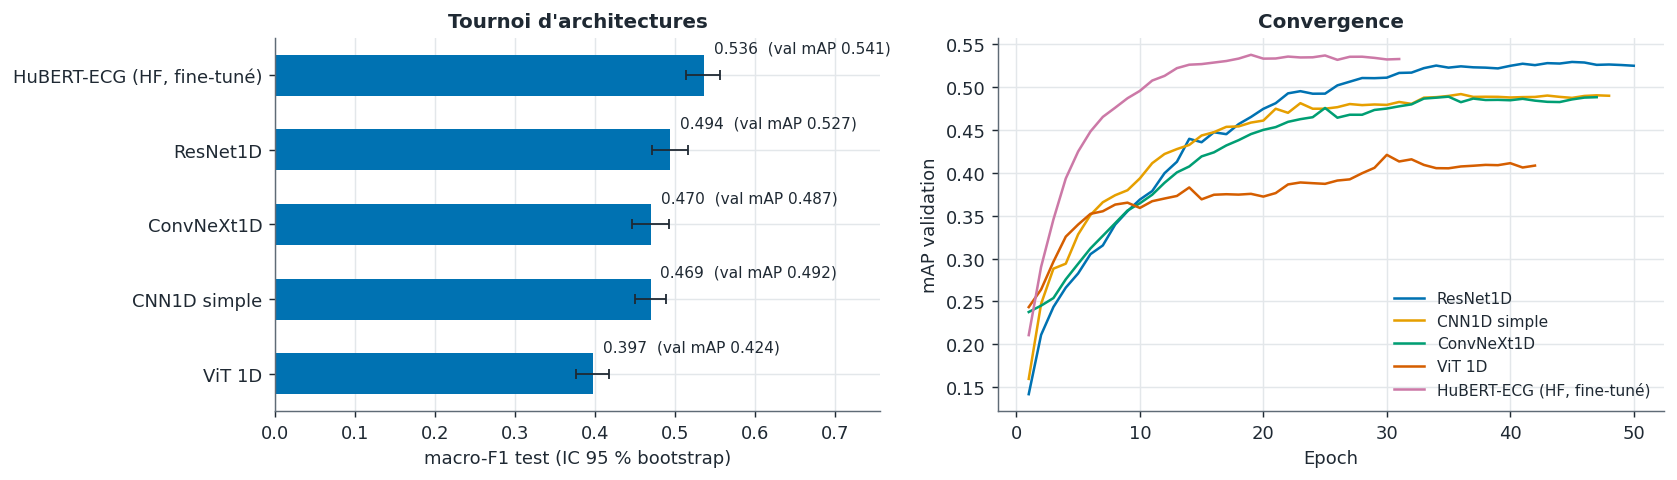

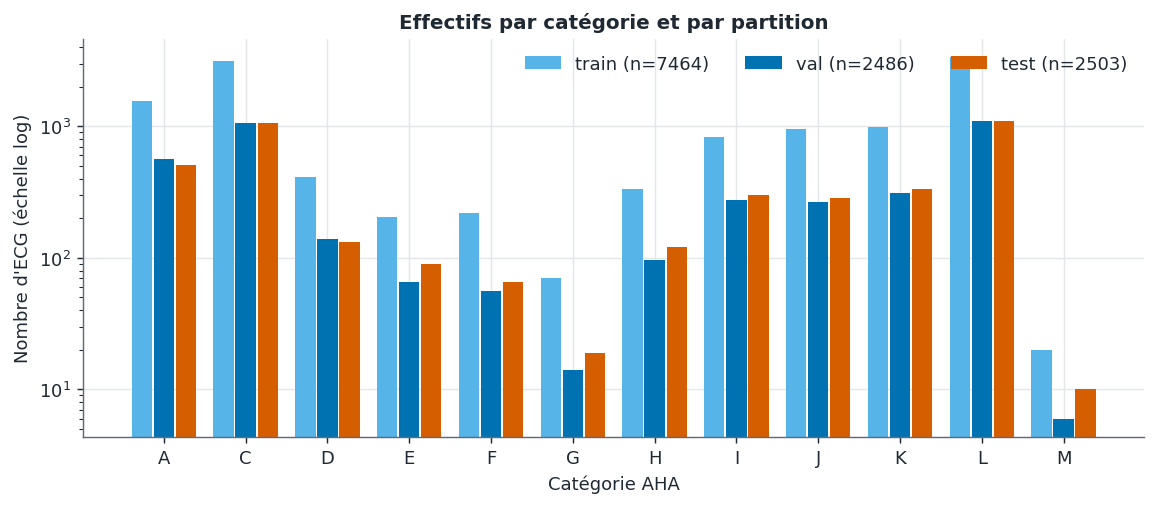

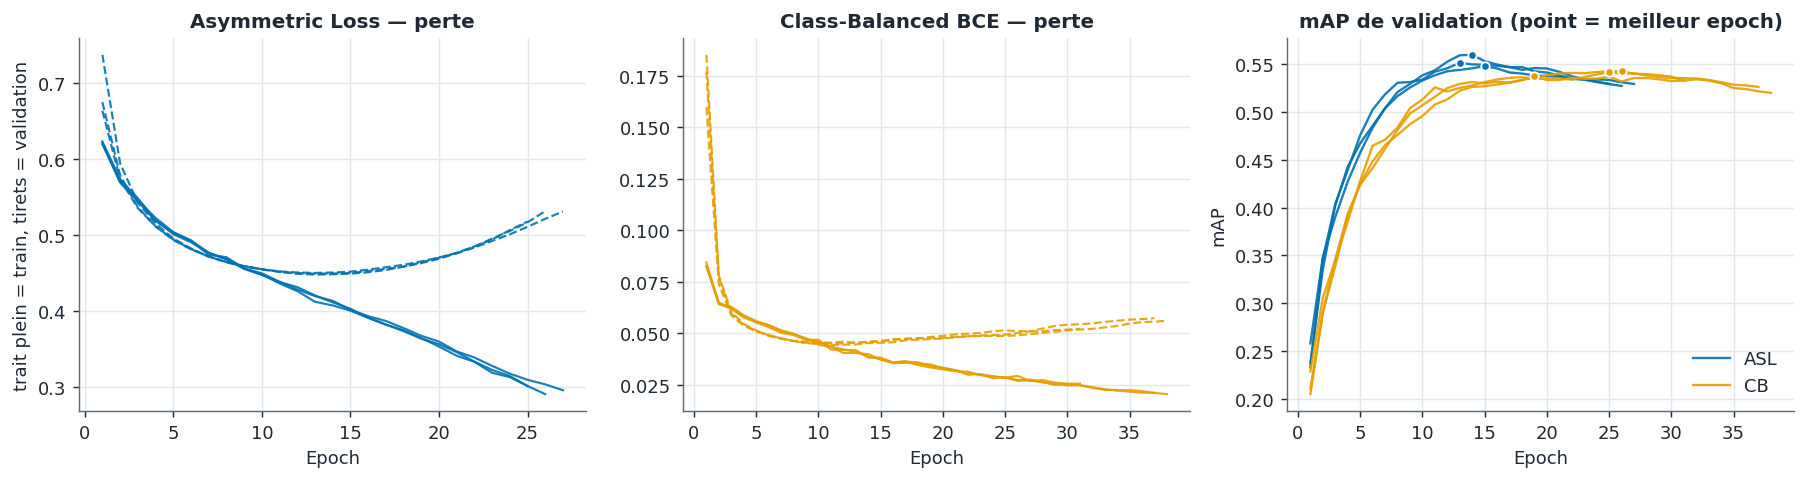

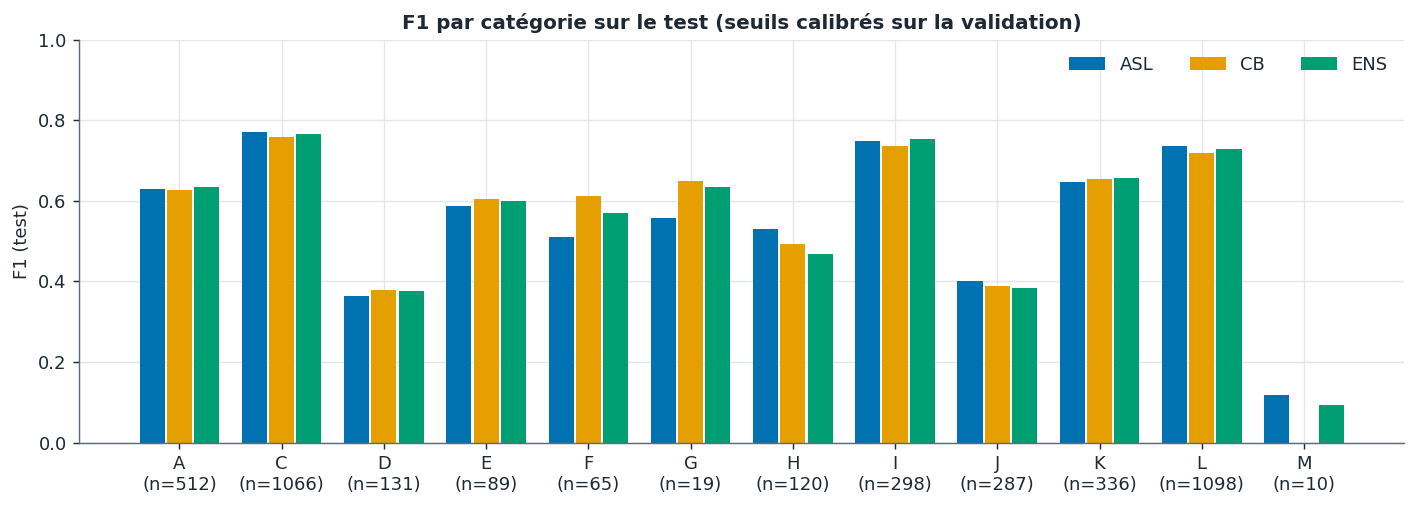

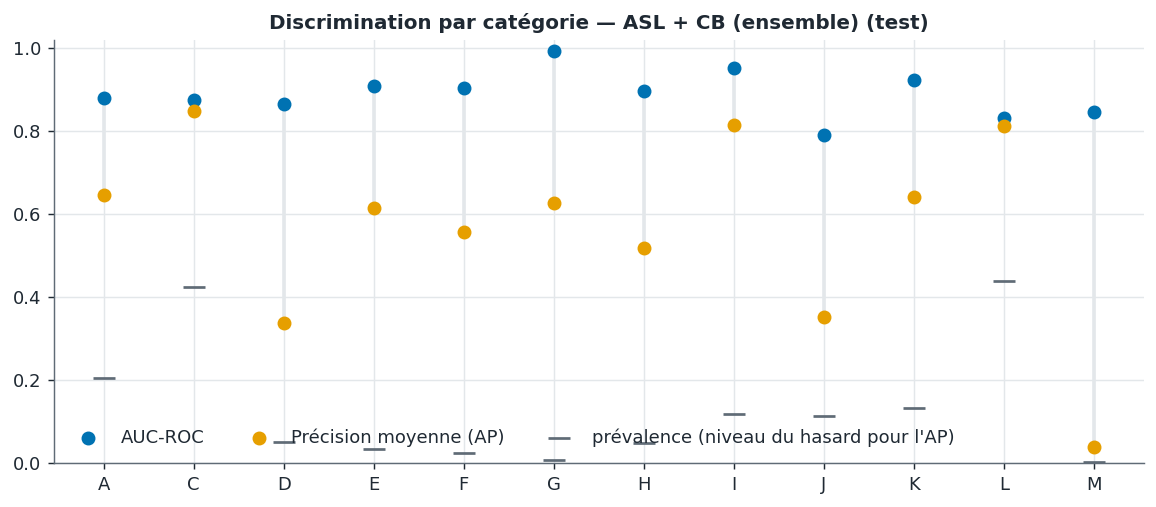

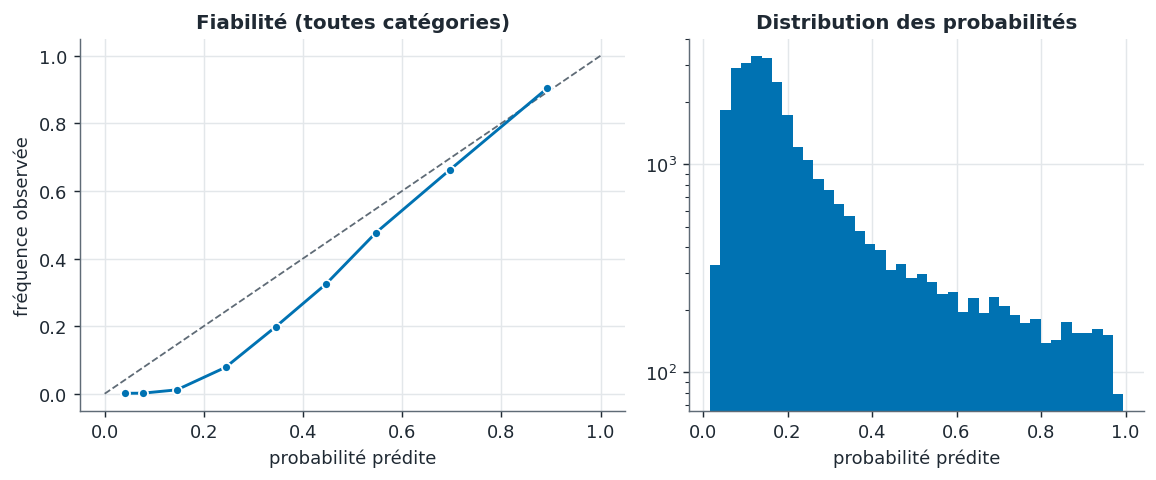

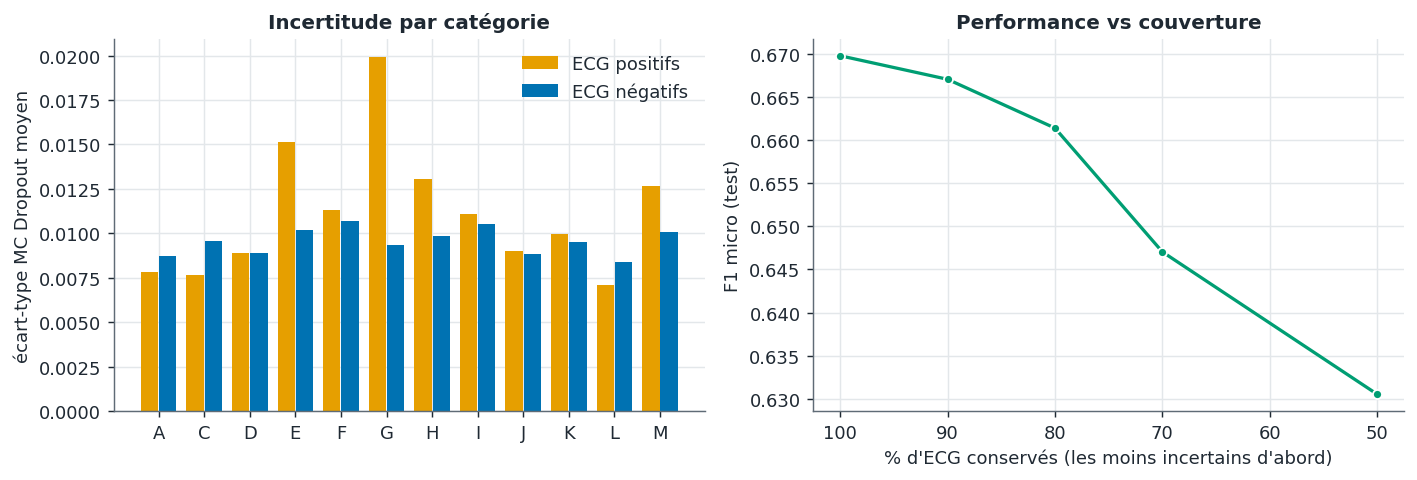

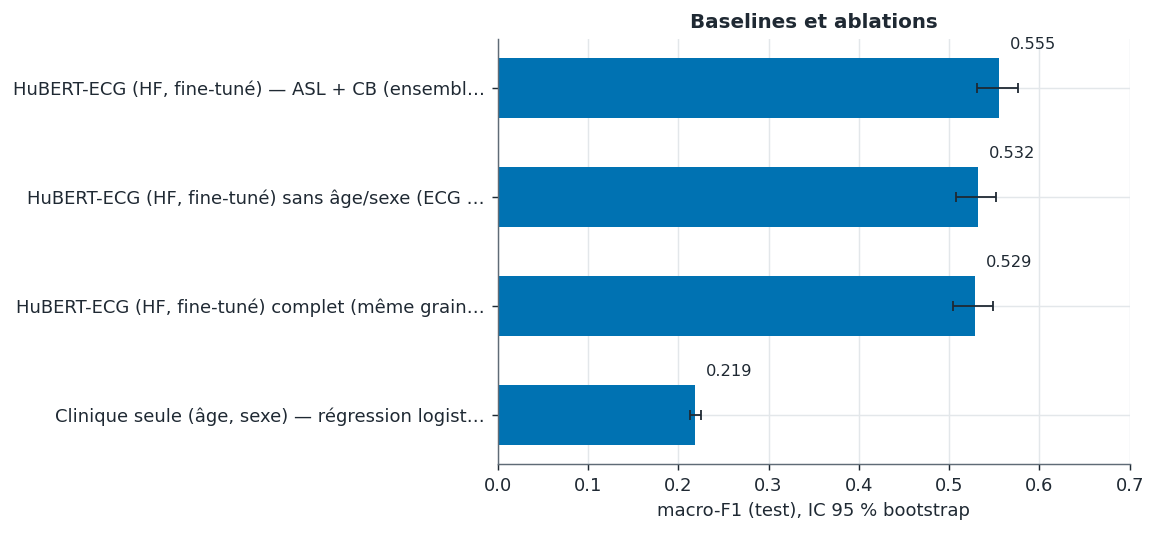

Figures enregistrées dans /kaggle/working/results/figures


In [19]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = "#1f2933", "#5f6b76", "#e3e7ea"
C_ASL, C_CB, C_ENS = "#0072B2", "#E69F00", "#009E73"            # Okabe-Ito (sûr pour le daltonisme)
C_SPLIT = {"train": "#56B4E9", "val": "#0072B2", "test": "#D55E00"}
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False})
COL = {"ASL": C_ASL, "CB": C_CB, "ENS": C_ENS}
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / name, bbox_inches="tight", facecolor="white"); plt.show(); plt.close(fig)

# 0. Tournoi d'architectures
if TOURN:
    d = tourn_df.sort_values("test_macro_F1"); fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.1]})
    y = np.arange(len(d)); axs[0].barh(y, d["test_macro_F1"], color=C_ASL, height=0.55)
    axs[0].errorbar(d["test_macro_F1"], y, xerr=[d["test_macro_F1"] - d["IC95_bas"], d["IC95_haut"] - d["test_macro_F1"]], fmt="none", ecolor=INK, lw=1, capsize=3)
    for yi, v, m in zip(y, d["test_macro_F1"], d["val_mAP (critère)"]): axs[0].text(v + 0.012, yi + 0.3, f"{v:.3f}  (val mAP {m:.3f})", fontsize=8.5)
    axs[0].set_yticks(y, d["architecture"]); axs[0].set_xlim(0, max(0.7, d["IC95_haut"].max() + 0.2)); axs[0].set_xlabel("macro-F1 test (IC 95 % bootstrap)"); axs[0].set_title("Tournoi d'architectures")
    ac = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"]
    for k, (arch, r) in enumerate(TOURN.items()):
        h = json.loads(str(r["history"])); axs[1].plot(np.arange(1, len(h["val_map"]) + 1), h["val_map"], color=ac[k % 5], lw=1.4, label=ARCH_LABELS[arch])
    axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("mAP validation"); axs[1].set_title("Convergence"); axs[1].legend(fontsize=8.5, loc="lower right")
    save(fig, "fig_architecture_tournament.png")

# 1. Distribution des catégories par partition
fig, ax = plt.subplots(figsize=(9, 4)); w = 0.27; x = np.arange(N_CLASSES)
for k, (nm, Y) in enumerate((("train", train_labels), ("val", val_labels), ("test", test_labels))):
    ax.bar(x + (k - 1) * w, Y.sum(0), w * 0.92, color=C_SPLIT[nm], label=f"{nm} (n={len(Y)})")
ax.set_yscale("log"); ax.set_xticks(x, CATEGORIES); ax.set_ylabel("Nombre d'ECG (échelle log)"); ax.set_xlabel("Catégorie AHA")
ax.set_title("Effectifs par catégorie et par partition"); ax.legend(ncol=3, loc="upper right")
save(fig, "fig_label_distribution.png")

# 2. Courbes d'entraînement (toutes graines)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for (l, s), r in sorted(RUNS.items()):
    h = json.loads(str(r["history"])); ep = np.arange(1, len(h["val_loss"]) + 1); c = COL[l]
    a = axs[0] if l == "ASL" else axs[1]
    a.plot(ep, h["train_loss"], color=c, lw=1.2, alpha=0.9); a.plot(ep, h["val_loss"], color=c, lw=1.2, ls="--", alpha=0.9)
    axs[2].plot(ep, h["val_map"], color=c, lw=1.3, alpha=0.9, label=l if s == seeds_of(l)[0] else None)
    axs[2].scatter([int(r["best_epoch"])], [h["val_map"][int(r["best_epoch"]) - 1]], color=c, s=22, zorder=3, edgecolor="white")
axs[0].set_title("Asymmetric Loss — perte"); axs[1].set_title("Class-Balanced BCE — perte"); axs[2].set_title("mAP de validation (point = meilleur epoch)")
for a in axs: a.set_xlabel("Epoch")
axs[0].set_ylabel("trait plein = train, tirets = validation"); axs[2].set_ylabel("mAP"); axs[2].legend()
save(fig, "fig_training_curves.png")

# 3. F1 par catégorie (test) — candidats
fig, ax = plt.subplots(figsize=(11, 4)); names = list(EVAL.keys()); w = 0.8 / len(names)
for k, n in enumerate(names):
    ax.bar(np.arange(N_CLASSES) + (k - (len(names) - 1) / 2) * w, EVAL[n]["rep"]["f1"], w * 0.92, color=COL[n], label=n)
ax.set_xticks(np.arange(N_CLASSES), [f"{c}\n(n={int(s)})" for c, s in zip(CATEGORIES, EVAL[BEST]["rep"]["support"])])
ax.set_ylabel("F1 (test)"); ax.set_ylim(0, 1); ax.set_title("F1 par catégorie sur le test (seuils calibrés sur la validation)"); ax.legend(ncol=3)
save(fig, "fig_f1_per_category.png")

# 4. AUC et AP par catégorie (modèle retenu)
fig, ax = plt.subplots(figsize=(9, 4)); rp = best["rep"]; x = np.arange(N_CLASSES)
ax.vlines(x, rp["auc"], rp["ap"], color=GRID, lw=2)
ax.scatter(x, rp["auc"], color=C_ASL, s=45, label="AUC-ROC", zorder=3); ax.scatter(x, rp["ap"], color=C_CB, s=45, label="Précision moyenne (AP)", zorder=3)
ax.scatter(x, rp["support"] / len(test_labels), marker="_", color=MUTED, s=140, label="prévalence (niveau du hasard pour l'AP)", zorder=3)
ax.set_xticks(x, CATEGORIES); ax.set_ylim(0, 1.02); ax.set_title(f"Discrimination par catégorie — {NAMES[BEST]} (test)"); ax.legend(loc="lower left", ncol=3)
save(fig, "fig_auc_ap_per_category.png")

# 5. Calibration (fiabilité) — probabilités poolées sur les 12 sorties
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
pf, yf = CANDS[BEST]["test"].ravel(), test_labels.ravel(); bins = np.array([0, .02, .05, .1, .2, .3, .4, .5, .6, .8, 1.0001])
idx = np.digitize(pf, bins) - 1; cx, cy = [], []
for b in range(len(bins) - 1):
    m = idx == b
    if m.sum() >= 20: cx.append(pf[m].mean()); cy.append(yf[m].mean())
axs[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1); axs[0].plot(cx, cy, color=C_ASL, lw=1.6, marker="o", ms=5, mec="white")
axs[0].set_xlabel("probabilité prédite"); axs[0].set_ylabel("fréquence observée"); axs[0].set_title("Fiabilité (toutes catégories)")
axs[1].hist(pf, bins=40, color=C_ASL, log=True); axs[1].set_xlabel("probabilité prédite"); axs[1].set_title("Distribution des probabilités")
save(fig, "fig_calibration.png")

# 6. Incertitude MC Dropout
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(N_CLASSES); axs[0].bar(x - 0.2, unc_cat["incertitude_si_positif"], 0.38, color=C_CB, label="ECG positifs"); axs[0].bar(x + 0.2, unc_cat["incertitude_si_negatif"], 0.38, color=C_ASL, label="ECG négatifs")
axs[0].set_xticks(x, CATEGORIES); axs[0].set_ylabel("écart-type MC Dropout moyen"); axs[0].set_title("Incertitude par catégorie"); axs[0].legend()
axs[1].plot(cov_df["fraction_gardee"] * 100, cov_df["micro_F1"], color=C_ENS, lw=1.8, marker="o", ms=5, mec="white")
axs[1].set_xlabel("% d'ECG conservés (les moins incertains d'abord)"); axs[1].set_ylabel("F1 micro (test)"); axs[1].set_title("Performance vs couverture"); axs[1].invert_xaxis()
save(fig, "fig_uncertainty.png")

# 7. Baselines / ablations
if ABL:
    d = pd.read_csv(RES_DIR / "ablation_baselines.csv").sort_values("test_macro_F1")
    fig, ax = plt.subplots(figsize=(9, 3.2 + 0.25 * len(d)))
    y = np.arange(len(d)); ax.barh(y, d["test_macro_F1"], color=C_ASL, height=0.55)
    ax.errorbar(d["test_macro_F1"], y, xerr=[d["test_macro_F1"] - d["IC95_bas"], d["IC95_haut"] - d["test_macro_F1"]], fmt="none", ecolor=INK, lw=1, capsize=3)
    for yi, v in zip(y, d["test_macro_F1"]): ax.text(v + 0.012, yi + 0.33, f"{v:.3f}", va="bottom", fontsize=9)
    ax.set_yticks(y, [t if len(t) < 48 else t[:46] + "…" for t in d["modele"]]); ax.set_xlabel("macro-F1 (test), IC 95 % bootstrap"); ax.set_xlim(0, max(0.7, d["IC95_haut"].max() + 0.06))
    ax.set_title("Baselines et ablations"); save(fig, "fig_ablation.png")
print("Figures enregistrées dans", FIG_DIR)

## 10bis. Approche probabiliste : calibration, incertitude, prédiction conforme, seuils sécurité

1. CALIBRATION (test) — le choix se fait sur la NLL de validation :
         calibration  val_NLL  test_NLL  test_Brier  test_ECE_global  test_ECE_moy_par_categorie(>=30 pos.)
                brut   0.2803    0.2823      0.0762           0.1133                                 0.1253
température (T=0.47)   0.2117    0.2163      0.0642           0.0280                                 0.0424
 Platt par catégorie   0.2068    0.2111      0.0623           0.0151                                 0.0227
>>> calibration retenue : Platt par catégorie | macro-F1 test après recalibrage des seuils : 0.5511 (avant : 0.5550)

2. L'INCERTITUDE DÉTECTE-T-ELLE LES ERREURS ? (AUC 0,5 = hasard ; plus haut = mieux)
                              mesure  AUC_detection_erreur_par_etiquette  AUC_detection_erreur_par_ECG
     Entropie (probabilité calibrée)                               0.883                         0.757
Désaccord entre modèles (écart-type)                               0.504                   

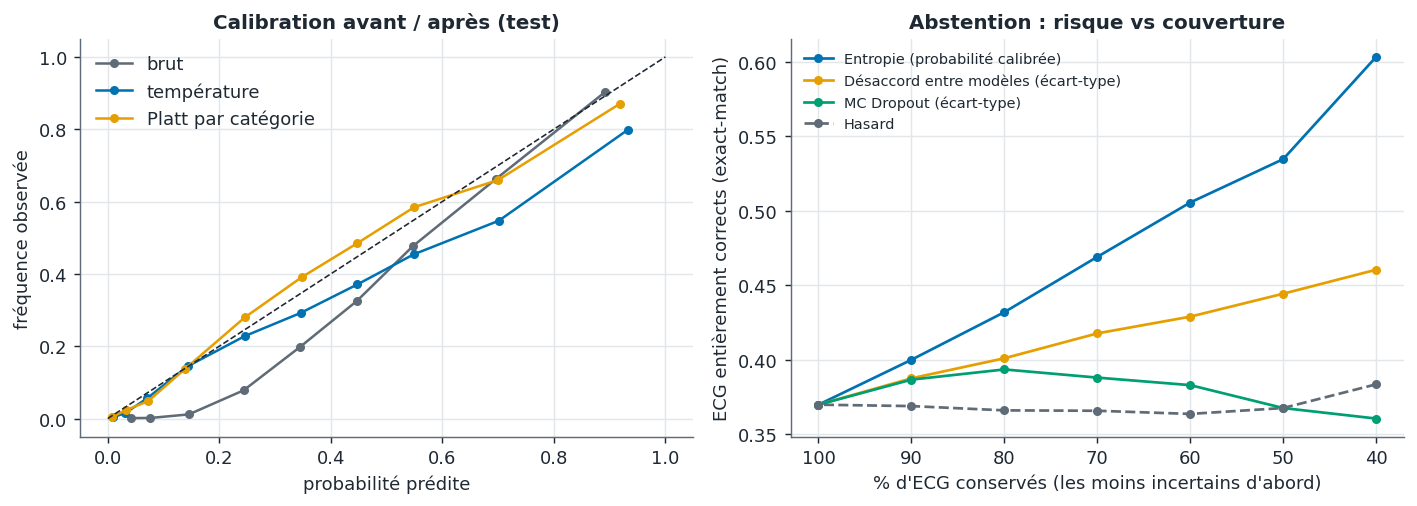

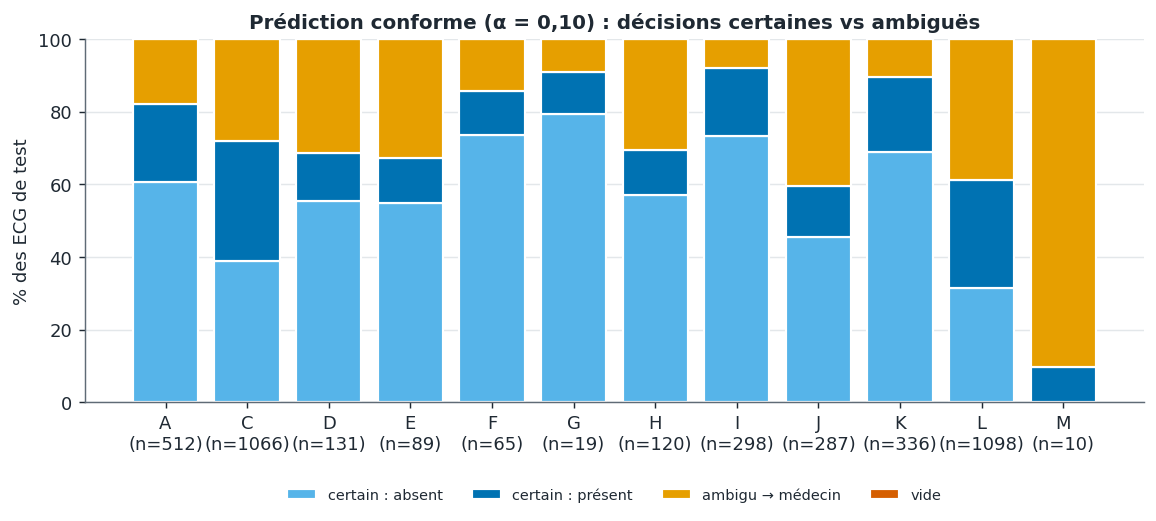

In [20]:
# ======================= APPROCHE PROBABILISTE (sans IA générative) : calibration, incertitude, prédiction conforme =======================
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression
EPS = 1e-6
def logit(p): p = np.clip(p, EPS, 1 - EPS); return np.log(p / (1 - p))
def sigm(z): return 1 / (1 + np.exp(-z))
def nll(p, y): p = np.clip(p, EPS, 1 - EPS); return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
def brier(p, y): return float(np.mean((p - y) ** 2))
def ece(p, y, n_bins=15):
    p, y = p.ravel(), y.ravel(); b = np.minimum((p * n_bins).astype(int), n_bins - 1); e = 0.0
    for k in range(n_bins):
        m = b == k
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(e)
def ece_cls(P, Y, min_pos=30):
    return float(np.nanmean([ece(P[:, i], Y[:, i]) if Y[:, i].sum() >= min_pos else np.nan for i in range(N_CLASSES)]))

PV, PT = CANDS[BEST]["val"], CANDS[BEST]["test"]
RUN_PT = np.stack([RUNS[k]["test_probs"] for k in sorted(RUNS)])                  # (n_runs, N, 12)

# ---- 1. Calibration : température globale ou Platt par catégorie, ajustée sur la VALIDATION ----
zv, zt = logit(PV), logit(PT)
T = float(minimize_scalar(lambda t: nll(sigm(zv / t), val_labels), bounds=(0.3, 5.0), method="bounded").x)
cal_methods = {"brut": (PV, PT), f"température (T={T:.2f})": (sigm(zv / T), sigm(zt / T))}
pv_pl, pt_pl = PV.copy(), PT.copy()
for i in range(N_CLASSES):
    if val_labels[:, i].sum() >= 10:
        lr_ = LogisticRegression(C=1e4, max_iter=1000).fit(zv[:, [i]], val_labels[:, i])
        pv_pl[:, i], pt_pl[:, i] = lr_.predict_proba(zv[:, [i]])[:, 1], lr_.predict_proba(zt[:, [i]])[:, 1]
cal_methods["Platt par catégorie"] = (pv_pl, pt_pl)
rows = [{"calibration": n, "val_NLL": nll(v, val_labels), "test_NLL": nll(t, test_labels), "test_Brier": brier(t, test_labels),
         "test_ECE_global": ece(t, test_labels), "test_ECE_moy_par_categorie(>=30 pos.)": ece_cls(t, test_labels)} for n, (v, t) in cal_methods.items()]
cal_df = pd.DataFrame(rows); cal_df.to_csv(RES_DIR / "calibration.csv", index=False)
print("1. CALIBRATION (test) — le choix se fait sur la NLL de validation :"); print(cal_df.round(4).to_string(index=False))
CAL_NAME = min(cal_methods, key=lambda n: nll(cal_methods[n][0], val_labels))
PVc, PTc = cal_methods[CAL_NAME]
THRc = calibrate_thresholds(PVc, val_labels); repc, summc = full_report(PTc, test_labels, THRc)
print(f">>> calibration retenue : {CAL_NAME} | macro-F1 test après recalibrage des seuils : {summc['macro_f1']:.4f} (avant : {best['summ']['macro_f1']:.4f})")

# ---- 2. Scores d'incertitude et détection d'erreur ----
def Hb(p): p = np.clip(p, EPS, 1 - EPS); return -(p * np.log(p) + (1 - p) * np.log(1 - p))
predc = (PTc >= THRc[None, :]).astype(int); wrong_pair = (predc != test_labels.astype(int)); wrong_rec = wrong_pair.any(1)
U_pair = {"Entropie (probabilité calibrée)": Hb(PTc), "Désaccord entre modèles (écart-type)": RUN_PT.std(0), "MC Dropout (écart-type)": mc_std}
U_rec = {k: v.mean(1) for k, v in U_pair.items()}
rows = [{"mesure": k, "AUC_detection_erreur_par_etiquette": safe_auc(wrong_pair.ravel().astype(float), U_pair[k].ravel()),
         "AUC_detection_erreur_par_ECG": safe_auc(wrong_rec.astype(float), U_rec[k])} for k in U_pair]
unc_df = pd.DataFrame(rows); unc_df.to_csv(RES_DIR / "uncertainty_error_detection.csv", index=False)
print("\n2. L'INCERTITUDE DÉTECTE-T-ELLE LES ERREURS ? (AUC 0,5 = hasard ; plus haut = mieux)"); print(unc_df.round(3).to_string(index=False))

# Courbe risque-couverture : on garde les ECG les moins incertains
cov_grid = np.array([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]); rc_rows = []; rng_ = np.random.default_rng(0)
for k, u in list(U_rec.items()) + [("Hasard", rng_.random(len(wrong_rec)))]:
    order = np.argsort(u)
    for f in cov_grid:
        idx = order[: max(int(f * len(order)), 1)]
        rc_rows.append({"mesure": k, "couverture": f, "exact_match": float((~wrong_rec[idx]).mean()),
                        "micro_F1": f1_score(test_labels[idx], predc[idx], average="micro", zero_division=0)})
rc_df = pd.DataFrame(rc_rows); rc_df.to_csv(RES_DIR / "risk_coverage.csv", index=False)
print("\n   Exact-match en ne gardant que x % des ECG (les moins incertains) :")
print(rc_df.pivot(index="couverture", columns="mesure", values="exact_match").round(3).to_string())

# ---- 3. Prédiction conforme multi-label (split conformal, conditionnelle à la classe et au label ; calibrée sur la validation) ----
def conformal(pv, yv, pt, alpha):
    sets = np.zeros(pt.shape + (2,), bool); qs = np.zeros((N_CLASSES, 2))
    for c in range(N_CLASSES):
        for y in (0, 1):
            s = 1 - (pv[yv[:, c] == y, c] if y == 1 else 1 - pv[yv[:, c] == y, c]); n = len(s); k = int(np.ceil((n + 1) * (1 - alpha)))
            qs[c, y] = np.sort(s)[k - 1] if (k <= n and n > 0) else np.inf
            sets[:, c, y] = (1 - (pt[:, c] if y == 1 else 1 - pt[:, c])) <= qs[c, y]
    return sets, qs
yt = test_labels.astype(int); conf_rows, CONF = [], {}
for alpha in (0.05, 0.10, 0.20):
    sets, qs = conformal(PVc, val_labels.astype(int), PTc, alpha); CONF[alpha] = sets
    size = sets.sum(-1); single = size == 1; cover = np.take_along_axis(sets, yt[..., None], axis=2)[..., 0]
    pred_lab = sets[..., 1].astype(int); err_single = (pred_lab != yt) & single
    auto = single.all(1)
    conf_rows.append({"alpha": alpha, "couverture_positifs": float(cover[yt == 1].mean()), "couverture_negatifs": float(cover[yt == 0].mean()),
                      "pct_decisions_certaines": float(100 * single.mean()), "pct_ambigues({0,1})": float(100 * (size == 2).mean()),
                      "erreur_parmi_decisions_certaines": float(err_single.sum() / max(single.sum(), 1)),
                      "pct_ECG_entierement_automatiques": float(100 * auto.mean()),
                      "exact_match_ECG_automatiques": float(((pred_lab == yt).all(1))[auto].mean()) if auto.any() else np.nan})
conf_df = pd.DataFrame(conf_rows); conf_df.to_csv(RES_DIR / "conformal_summary.csv", index=False)
print("\n3. PRÉDICTION CONFORME (garantie : l'étiquette vraie est dans l'ensemble avec proba ≥ 1−α, par catégorie) :"); print(conf_df.round(3).to_string(index=False))
sets10 = CONF[0.10]; size10 = sets10.sum(-1); cov10 = np.take_along_axis(sets10, yt[..., None], axis=2)[..., 0]
pc_rows = [{"categorie": c, "support_test": int(yt[:, i].sum()), "support_val": int(val_labels[:, i].sum()),
            "couverture_positifs": float(cov10[yt[:, i] == 1, i].mean()), "couverture_negatifs": float(cov10[yt[:, i] == 0, i].mean()),
            "pct_certain_absent": float(100 * (sets10[:, i, 0] & ~sets10[:, i, 1]).mean()), "pct_certain_present": float(100 * (sets10[:, i, 1] & ~sets10[:, i, 0]).mean()),
            "pct_ambigu": float(100 * (size10[:, i] == 2).mean()), "pct_vide": float(100 * (size10[:, i] == 0).mean())} for i, c in enumerate(CATEGORIES)]
pc_df = pd.DataFrame(pc_rows); pc_df.to_csv(RES_DIR / "conformal_per_category_alpha10.csv", index=False)
print("\n   Détail par catégorie (α = 0,10) — une catégorie rare est « ambiguë » : le jeu de validation est trop petit pour la certifier :"); print(pc_df.round(2).to_string(index=False))

# ---- 4. Seuils orientés sécurité : rappel cible ≥ 90 % (on évite les faux négatifs) ----
rows = []
for i, c in enumerate(CATEGORIES):
    pv_i, yv_i, pt_i, yt_i = PVc[:, i], val_labels[:, i] > 0.5, PTc[:, i], test_labels[:, i] > 0.5
    ok = [t for t in THR_GRID if yv_i.sum() and ((pv_i >= t) & yv_i).sum() / yv_i.sum() >= 0.90]
    t = max(ok) if ok else THR_GRID[0]; p = pt_i >= t; tp = (p & yt_i).sum()
    rows.append({"categorie": c, "seuil_rappel90": round(float(t), 3), "rappel_test": tp / max(yt_i.sum(), 1), "precision_test": tp / max(p.sum(), 1),
                 "specificite_test": ((~p) & (~yt_i)).sum() / max((~yt_i).sum(), 1), "pct_ECG_signales": float(100 * p.mean())})
safe_df = pd.DataFrame(rows); safe_df.to_csv(RES_DIR / "safety_thresholds_recall90.csv", index=False)
print("\n4. SEUILS SÉCURITÉ (rappel ≥ 90 % sur la validation) :"); print(safe_df.round(3).to_string(index=False))

# ---- Figures ----
fig, axs = plt.subplots(1, 2, figsize=(11, 4)); bins = np.array([0, .02, .05, .1, .2, .3, .4, .5, .6, .8, 1.0001])
for (n, (v, t)), col in zip(cal_methods.items(), [MUTED, C_ASL, C_CB]):
    pf, yf = t.ravel(), test_labels.ravel(); idx = np.digitize(pf, bins) - 1; cx, cy = [], []
    for b in range(len(bins) - 1):
        m = idx == b
        if m.sum() >= 20: cx.append(pf[m].mean()); cy.append(yf[m].mean())
    axs[0].plot(cx, cy, marker="o", ms=4, lw=1.4, color=col, label=n.split(" (")[0])
axs[0].plot([0, 1], [0, 1], color=INK, ls="--", lw=0.9); axs[0].set_xlabel("probabilité prédite"); axs[0].set_ylabel("fréquence observée"); axs[0].set_title("Calibration avant / après (test)"); axs[0].legend()
for k, col in zip(list(U_rec) + ["Hasard"], [C_ASL, C_CB, C_ENS, MUTED]):
    d = rc_df[rc_df.mesure == k]; axs[1].plot(d["couverture"] * 100, d["exact_match"], marker="o", ms=4, lw=1.5, color=col, ls="--" if k == "Hasard" else "-", label=k)
axs[1].set_xlabel("% d'ECG conservés (les moins incertains d'abord)"); axs[1].set_ylabel("ECG entièrement corrects (exact-match)"); axs[1].set_title("Abstention : risque vs couverture"); axs[1].invert_xaxis(); axs[1].legend(fontsize=8)
save(fig, "fig_calibration_abstention.png")
fig, ax = plt.subplots(figsize=(9, 4.2)); x = np.arange(N_CLASSES); bottom = np.zeros(N_CLASSES)
for col_, lab, colr in (("pct_certain_absent", "certain : absent", "#56B4E9"), ("pct_certain_present", "certain : présent", "#0072B2"), ("pct_ambigu", "ambigu → médecin", "#E69F00"), ("pct_vide", "vide", "#D55E00")):
    ax.bar(x, pc_df[col_], 0.8, bottom=bottom, color=colr, label=lab, edgecolor="white", linewidth=1.2); bottom += pc_df[col_].values
ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(CATEGORIES, pc_df["support_test"])]); ax.set_ylabel("% des ECG de test"); ax.set_title("Prédiction conforme (α = 0,10) : décisions certaines vs ambiguës")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2)); save(fig, "fig_conformal.png")
PROBA_SUMMARY = {"calibration_retenue": CAL_NAME, "ECE_global_avant": float(cal_df.iloc[0]["test_ECE_global"]), "ECE_global_apres": float(cal_df[cal_df.calibration == CAL_NAME]["test_ECE_global"].iloc[0]),
                 "detection_erreur_AUC_par_ECG": {r["mesure"]: float(r["AUC_detection_erreur_par_ECG"]) for _, r in unc_df.iterrows()},
                 "conforme_alpha10": conf_df[conf_df.alpha == 0.10].iloc[0].to_dict()}

## 11. Sauvegarde du modèle et archive des résultats

In [22]:
# ======================= SAUVEGARDE FINALE =======================
winner_runs = [(l, s) for (l, s) in RUNS if BEST == "ENS" or l == BEST]
bundle = {"models": [{"loss": l, "seed": s, "state_dict": torch.load(MODELS_DIR / f"{run_tag(l, s, BEST_ARCH)}_best.pt", map_location="cpu")} for l, s in winner_runs],
          "thresholds": dict(zip(CATEGORIES, map(float, best["thr"]))), "categories": CATEGORIES, "strategy": BEST, "architecture": BEST_ARCH, "hf_id": (HF_IDS_BASE[0] if BEST_ARCH == "hubert_base" else HF_IDS[0] if BEST_ARCH == "hubert" else None), "n_leads": N_LEADS,
          "preprocessing": {"sample_rate": SAMPLE_RATE, "window_sec": WINDOW_SEC, "n_eval_windows": N_EVAL_WIN, "norm_mode": NORM_MODE,
                            "baseline_removal_1s_moving_average": BASELINE_REMOVAL, "clip": 10.0, "age_scale_years": AGE_SCALE,
                            "clinical_features": ["age_years/15 (clip 0..1.2)", "sexe masculin (0/1)", "nb dérivations réelles/12"]}}
torch.save(bundle, MODELS_DIR / "dawn_ecg_model_final.pt")
json.dump(bundle["thresholds"], open(MODELS_DIR / "dawn_ecg_thresholds.json", "w"), indent=2)
print("Modèle(s) sauvegardé(s) :", [f"{l}_s{s}" for l, s in winner_runs])

# Contrôle d'intégrité : on recharge le 1er modèle du bundle et on compare à ce qui a été mesuré
l0, s0 = winner_runs[0]; chk = build_model(BEST_ARCH).to(DEVICE); chk.load_state_dict(bundle["models"][0]["state_dict"])
p_chk, _ = predict(chk, make_eval_loader("test", N_EVAL_WIN), N_EVAL_WIN)
print(f"Contrôle rechargement : écart moyen avec les probabilités mesurées = {np.abs(p_chk - RUNS[(l0, s0)]['test_probs']).mean():.5f} (doit être ≈ 0)")

# Probabilités + étiquettes pour d'éventuelles analyses supplémentaires
np.savez_compressed(RES_DIR / "predictions_test_val.npz", val_labels=val_labels, test_labels=test_labels,
                    **{f"{n}_val": CANDS[n]["val"] for n in CANDS}, **{f"{n}_test": CANDS[n]["test"] for n in CANDS},
                    mc_mean=mc_mean, mc_std=mc_std, categories=np.array(CATEGORIES))

summary = {"architecture_retenue": BEST_ARCH, "strategie_retenue": BEST, "pct_multi_label_total": MULTI_PCT_TOTAL, "n_ecg": {k: int(len(CACHE[k]["Y"])) for k in CACHE},
           "seeds": SEEDS, "n_epochs_max": N_EPOCHS, "norm_mode": NORM_MODE, "baseline_removal": BASELINE_REMOVAL,
           "test_summary": best["summ"], "test_macro_f1_IC95": best["ci"], "thresholds": bundle["thresholds"],
           "approche_probabiliste": PROBA_SUMMARY, "duree_totale_h": round(elapsed_h(), 2), "torch": torch.__version__,
           "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
json.dump(summary, open(RES_DIR / "summary.json", "w"), indent=2, ensure_ascii=False, default=float)
print("(figures et tableaux ci-dessus : ils sont aussi enregistrés dans results/ et dans l'archive zip)")

zip_path = WORK_DIR / "dawn_v5_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RES_DIR.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(WORK_DIR))
print(f"\n Terminé en {elapsed_h():.2f} h. À récupérer dans l'onglet Output : {zip_path.name} (+ ce notebook exécuté).")
print(json.dumps({k: summary[k] for k in ("architecture_retenue", "strategie_retenue", "test_summary", "test_macro_f1_IC95")}, indent=2, default=float))

Modèle(s) sauvegardé(s) : ['ASL_s42', 'CB_s42', 'ASL_s1337', 'CB_s1337', 'ASL_s2024', 'CB_s2024']
Contrôle rechargement : écart moyen avec les probabilités mesurées = 0.00000 (doit être ≈ 0)
(figures et tableaux ci-dessus : ils sont aussi enregistrés dans results/ et dans l'archive zip)

 Terminé en 3.10 h. À récupérer dans l'onglet Output : dawn_v5_results.zip (+ ce notebook exécuté).
{
  "architecture_retenue": "hubert",
  "strategie_retenue": "ENS",
  "test_summary": {
    "macro_f1": 0.5550425404742502,
    "micro_f1": 0.6640994608867862,
    "samples_f1": 0.6581280241487991,
    "macro_auc": 0.8893482133883777,
    "mAP": 0.5674842136531835,
    "hamming_loss": 0.10164469303502463,
    "exact_match": 0.33519776268477824
  },
  "test_macro_f1_IC95": [
    0.5303407250302847,
    0.5763448931709921
  ]
}


## Fin — que m'envoyer ?
1. **Ce notebook exécuté** (téléchargé depuis Kaggle avec ses sorties, *File → Download Notebook*).
2. **`dawn_v5_results.zip`** (onglet *Output*) : figures PNG, tableaux CSV, `summary.json`.

Le fichier `models/dawn_ecg_model_final.pt` contient le(s) modèle(s) + seuils + paramètres de prétraitement pour l'intégration au backend ; il n'est pas nécessaire pour rédiger les chapitres 4 et 5.